<a href="https://colab.research.google.com/github/Supan-Roy/financial-scam-analysis/blob/main/notebooks/11_distilbert_multilevel_synthetic_training.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
# ============================================================
# NOTEBOOK 11: DistilBERT Multi-Level Synthetic Training
# Cell 1: Environment Setup and Reproducibility
# ============================================================

import os
import sys
import json
import random
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import torch

from google.colab import drive

warnings.filterwarnings("ignore")

# ------------------------------------------------------------
# 1. Mount Google Drive
# ------------------------------------------------------------

drive.mount("/content/drive")

# ------------------------------------------------------------
# 2. Project paths
# ------------------------------------------------------------

PROJECT_ROOT = Path(
    "/content/drive/MyDrive/financial-scam-analysis"
)

DATA_DIR = PROJECT_ROOT / "data"
SYNTHETIC_DIR = DATA_DIR / "synthetic"
SPLITS_DIR = DATA_DIR / "splits"

MODEL_DIR = PROJECT_ROOT / "models" / "distilbert_multilevel"
OUTPUT_DIR = PROJECT_ROOT / "outputs" / "distilbert_multilevel"

MODEL_DIR.mkdir(parents=True, exist_ok=True)
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# ------------------------------------------------------------
# 3. Reproducibility
# ------------------------------------------------------------

SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

# ------------------------------------------------------------
# 4. Device configuration
# ------------------------------------------------------------

DEVICE = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("=" * 65)
print("NOTEBOOK 11: ENVIRONMENT INITIALIZED")
print("=" * 65)

print(f"Python version : {sys.version.split()[0]}")
print(f"PyTorch        : {torch.__version__}")
print(f"Device         : {DEVICE}")

if torch.cuda.is_available():
    print(f"GPU            : {torch.cuda.get_device_name(0)}")
    print(
        f"GPU memory     : "
        f"{torch.cuda.get_device_properties(0).total_memory / 1024**3:.2f} GB"
    )

print(f"\nProject root   : {PROJECT_ROOT}")
print(f"Data directory : {DATA_DIR}")
print(f"Model output   : {MODEL_DIR}")
print(f"Results output : {OUTPUT_DIR}")

assert PROJECT_ROOT.exists(), (
    f"Project directory not found: {PROJECT_ROOT}"
)

print("\nEnvironment setup completed successfully.")

Mounted at /content/drive
NOTEBOOK 11: ENVIRONMENT INITIALIZED
Python version : 3.13.16
PyTorch        : 2.14.1+cu130
Device         : cuda
GPU            : Tesla T4
GPU memory     : 14.56 GB

Project root   : /content/drive/MyDrive/financial-scam-analysis
Data directory : /content/drive/MyDrive/financial-scam-analysis/data
Model output   : /content/drive/MyDrive/financial-scam-analysis/models/distilbert_multilevel
Results output : /content/drive/MyDrive/financial-scam-analysis/outputs/distilbert_multilevel

Environment setup completed successfully.


In [5]:
# ============================================================
# Cell 2: Dataset File Discovery
# ============================================================

print("=" * 70)
print("DATASET FILE DISCOVERY")
print("=" * 70)

search_dirs = [
    DATA_DIR,
    DATA_DIR / "synthetic",
    DATA_DIR / "external_evaluation",
]

extensions = {".csv", ".json", ".parquet"}

for directory in search_dirs:
    print(f"\n[{directory}]")

    if not directory.exists():
        print("Directory does not exist.")
        continue

    files = sorted(
        path for path in directory.rglob("*")
        if path.is_file() and path.suffix.lower() in extensions
    )

    if not files:
        print("No matching dataset files found.")
        continue

    for path in files:
        size_mb = path.stat().st_size / (1024 ** 2)
        print(f"  {path.relative_to(PROJECT_ROOT)} ({size_mb:.2f} MB)")

print("\nDataset discovery completed.")

DATASET FILE DISCOVERY

[/content/drive/MyDrive/financial-scam-analysis/data]
  data/external_evaluation/balanced_binary_external_test.csv (5.34 MB)
  data/external_evaluation/expanded_binary_external_test.csv (24.21 MB)
  data/external_evaluation/external_fin_scam_curated.csv (2.81 MB)
  data/processed/llm_authored_financial_scams_processed.csv (8.55 MB)
  data/processed/real_fin_legit_processed.csv (210.16 MB)
  data/processed/real_fin_scam_processed.csv (23.14 MB)
  data/processed/synthetic_financial_scams_v3_1_processed.csv (14.74 MB)
  data/raw/llm_authored_financial_scams.csv (3.94 MB)
  data/raw/real_fin_legit.csv (140.05 MB)
  data/raw/real_fin_scam.csv (12.70 MB)
  data/raw/synthetic_financial_scams_v3_1.csv (9.41 MB)
  data/splits/split_assignments.csv (5.80 MB)
  data/splits/test.csv (23.34 MB)
  data/splits/train.csv (188.60 MB)
  data/splits/validation.csv (23.72 MB)

[/content/drive/MyDrive/financial-scam-analysis/data/synthetic]
Directory does not exist.

[/content/drive

In [4]:
# ============================================================
# Cell 3: Load and Audit Multi-Level Datasets
# ============================================================

V31_PATH = DATA_DIR / "processed" / "synthetic_financial_scams_v3_1_processed.csv"
LLM_PATH = DATA_DIR / "processed" / "llm_authored_financial_scams_processed.csv"

v31_df = pd.read_csv(V31_PATH)
llm_df = pd.read_csv(LLM_PATH)

print("=" * 75)
print("DATASET STRUCTURE AUDIT")
print("=" * 75)

for name, df in [
    ("V3.1 PROGRAMMATIC", v31_df),
    ("LLM-AUTHORED", llm_df)
]:
    print(f"\n{'-' * 75}")
    print(f"{name}")
    print(f"{'-' * 75}")

    print(f"Shape: {df.shape}")

    print("\nColumns:")
    print(df.columns.tolist())

    print("\nData types:")
    print(df.dtypes.to_string())

    print("\nFirst record:")
    display(df.head(1).T)

    if "split_partition" in df.columns:
        print("\nPartition distribution:")
        print(df["split_partition"].value_counts(dropna=False).to_string())

    print("\nMissing values:")
    print(df.isna().sum().to_string())

print("\nDataset loading and initial audit completed.")

DATASET STRUCTURE AUDIT

---------------------------------------------------------------------------
V3.1 PROGRAMMATIC
---------------------------------------------------------------------------
Shape: (7800, 36)

Columns:
['record_id', 'original_text', 'normalized_text', 'label', 'channel', 'original_channel', 'is_email_gateway', 'has_gateway_headers', 'source', 'source_url', 'source_license', 'source_record_id', 'is_synthetic', 'scam_subtype', 'fraudulent_intent', 'social_engineering_tactics', 'primary_intent_evidence', 'tactics_evidence', 'narrative_evidence', 'legitimate_category', 'email_subject', 'email_body', 'duplicate_cluster_id', 'split_partition', 'char_count_original', 'word_count_original', 'char_count_normalized', 'word_count_normalized', 'placeholder_count_original', 'placeholder_count_normalized', 'scenario_family', 'generation_template_id', 'generation_scenario', 'risk_or_safety_note', 'language', 'communication_type']

Data types:
record_id                        obje

,0
record_id,SYN31-00001
original_text,Action Required: We detected an unauthorized s...
normalized_text,Action Required: We detected an unauthorized s...
label,1
channel,sms
original_channel,sms
is_email_gateway,False
has_gateway_headers,False
source,synthetic_financial_scams_v3_corrected
source_url,local_generation_v3_corrected



Partition distribution:
split_partition
train    6240
val       780
test      780

Missing values:
record_id                          0
original_text                      0
normalized_text                    0
label                              0
channel                            0
original_channel                   0
is_email_gateway                   0
has_gateway_headers                0
source                             0
source_url                         0
source_license                     0
source_record_id                   0
is_synthetic                       0
scam_subtype                       0
fraudulent_intent                  0
social_engineering_tactics         0
primary_intent_evidence            0
tactics_evidence                   0
narrative_evidence                 0
legitimate_category             7800
email_subject                   5113
email_body                      5113
duplicate_cluster_id            7627
split_partition                    0
char_count_o

,0
id,LLM-SCAM-00001
text,hey heads up!! looks like someone tried loggin...
label,phishing
phishing_type,account_verification
scam_channel,sms
fraudulent_intent,obtain_credentials_or_codes
social_engineering_tactics,"[""urgency"", ""fear_or_threat"", ""false_legitimacy""]"
primary_intent_evidence,quickly lock your profile and secure your pass...
primary_intent_start,147
primary_intent_end,246



Partition distribution:
split_partition
train    2184
val       273
test      273

Missing values:
id                                  0
text                                0
label                               0
phishing_type                       0
scam_channel                        0
fraudulent_intent                   0
social_engineering_tactics          0
primary_intent_evidence             0
primary_intent_start                0
primary_intent_end                  0
tactics_evidence                    0
writing_style                       0
email_subject                    1585
optional_scenario_description     403
urgency_rating                    382
secondary_channel_source          423
scenario_family                     0
synthetic                           0
generation_method                   0
model_provenance                    0
language                            0
original_text                       0
normalized_text                     0
char_count_original       

,0
record_id,SYN31-00001
original_text,Action Required: We detected an unauthorized s...
normalized_text,Action Required: We detected an unauthorized s...
label,1
channel,sms
original_channel,sms
is_email_gateway,False
has_gateway_headers,False
source,synthetic_financial_scams_v3_corrected
source_url,local_generation_v3_corrected



Partition distribution:
split_partition
train    6240
val       780
test      780

Missing values:
record_id                          0
original_text                      0
normalized_text                    0
label                              0
channel                            0
original_channel                   0
is_email_gateway                   0
has_gateway_headers                0
source                             0
source_url                         0
source_license                     0
source_record_id                   0
is_synthetic                       0
scam_subtype                       0
fraudulent_intent                  0
social_engineering_tactics         0
primary_intent_evidence            0
tactics_evidence                   0
narrative_evidence                 0
legitimate_category             7800
email_subject                   5113
email_body                      5113
duplicate_cluster_id            7627
split_partition                    0
char_count_o

,0
id,LLM-SCAM-00001
text,hey heads up!! looks like someone tried loggin...
label,phishing
phishing_type,account_verification
scam_channel,sms
fraudulent_intent,obtain_credentials_or_codes
social_engineering_tactics,"[""urgency"", ""fear_or_threat"", ""false_legitimacy""]"
primary_intent_evidence,quickly lock your profile and secure your pass...
primary_intent_start,147
primary_intent_end,246



Partition distribution:
split_partition
train    2184
val       273
test      273

Missing values:
id                                  0
text                                0
label                               0
phishing_type                       0
scam_channel                        0
fraudulent_intent                   0
social_engineering_tactics          0
primary_intent_evidence             0
primary_intent_start                0
primary_intent_end                  0
tactics_evidence                    0
writing_style                       0
email_subject                    1585
optional_scenario_description     403
urgency_rating                    382
secondary_channel_source          423
scenario_family                     0
synthetic                           0
generation_method                   0
model_provenance                    0
language                            0
original_text                       0
normalized_text                     0
char_count_original       

In [6]:
# ============================================================
# Cell 4: Multi-Level Label and Annotation Audit
# ============================================================

import json
import ast

def parse_tactics(value):
    """Parse a serialized tactic list safely."""
    if pd.isna(value) or not str(value).strip():
        return []

    try:
        parsed = json.loads(value)
    except (json.JSONDecodeError, TypeError):
        try:
            parsed = ast.literal_eval(value)
        except (ValueError, SyntaxError):
            return []

    return parsed if isinstance(parsed, list) else []


datasets = {
    "V3.1": v31_df,
    "LLM": llm_df
}

TASK_COLUMNS = {
    "Subtype": "scam_subtype",
    "Intent": "fraudulent_intent",
    "Tactics": "social_engineering_tactics"
}

TACTIC_CLASSES = [
    "authority_impersonation",
    "emotional_manipulation",
    "false_legitimacy",
    "fear_or_threat",
    "reward_or_benefit",
    "scarcity",
    "secrecy",
    "trust_exploitation",
    "urgency"
]

print("=" * 75)
print("MULTI-LEVEL LABEL AUDIT")
print("=" * 75)

for dataset_name, df in datasets.items():
    print(f"\n{'=' * 75}")
    print(f"{dataset_name} DATASET")
    print(f"{'=' * 75}")

    for task_name, column in TASK_COLUMNS.items():
        print(f"\n{task_name} distribution:")

        if task_name == "Tactics":
            parsed = df[column].apply(parse_tactics)
            annotated = parsed.apply(lambda x: len(x) > 0)

            print(f"Total records       : {len(df)}")
            print(f"Annotated records   : {annotated.sum()}")
            print(f"Unannotated records : {(~annotated).sum()}")

            tactic_counts = pd.Series(
                [tactic for labels in parsed for tactic in labels]
            ).value_counts()

            print("\nIndividual tactic occurrences:")
            print(tactic_counts.to_string())

            unknown = set(tactic_counts.index) - set(TACTIC_CLASSES)
            assert not unknown, f"Unknown tactic labels: {unknown}"

        else:
            counts = df[column].value_counts(dropna=False)
            print(counts.to_string())

            assert df[column].notna().all(), (
                f"Missing labels found in {dataset_name}: {column}"
            )

    print("\nPartition sizes:")
    print(df["split_partition"].value_counts().to_string())


# ------------------------------------------------------------
# Cross-dataset class consistency
# ------------------------------------------------------------

print("\n" + "=" * 75)
print("CROSS-DATASET CLASS CONSISTENCY")
print("=" * 75)

for task_name, column in [
    ("Subtype", "scam_subtype"),
    ("Intent", "fraudulent_intent")
]:
    v31_classes = set(v31_df[column].unique())
    llm_classes = set(llm_df[column].unique())

    print(f"\n{task_name}")
    print(f"V3.1 classes : {len(v31_classes)}")
    print(f"LLM classes  : {len(llm_classes)}")
    print(f"Shared       : {len(v31_classes & llm_classes)}")

    if v31_classes != llm_classes:
        print("Only in V3.1:", sorted(v31_classes - llm_classes))
        print("Only in LLM :", sorted(llm_classes - v31_classes))

    assert v31_classes == llm_classes, (
        f"{task_name} classes differ between datasets."
    )

print("\nExpected tactic classes:", len(TACTIC_CLASSES))
print("Label and annotation audit completed.")

MULTI-LEVEL LABEL AUDIT

V3.1 DATASET

Subtype distribution:
scam_subtype
account_verification              600
card_transaction_alert            600
refund_chargeback                 600
invoice_payment_request           600
loan_offer                        600
investment_crypto                 600
prize_reward                      600
tax_payment                       600
job_task_commission               600
romance_financial_manipulation    600
family_emergency_request          600
recovery_support                  600
charity_donation                  600

Intent distribution:
fraudulent_intent
induce_payment_or_transfer                  3684
obtain_personal_or_financial_information    1792
obtain_credentials_or_codes                 1160
gain_account_or_device_access                582
induce_fraudulent_investment                 582

Tactics distribution:
Total records       : 7800
Annotated records   : 6450
Unannotated records : 1350

Individual tactic occurrences:
urgency    

In [7]:
# ============================================================
# Cell 5: Partition-Level Annotation Verification
# ============================================================

print("=" * 75)
print("TACTIC ANNOTATION BY PARTITION")
print("=" * 75)

annotation_summary = []

for dataset_name, df in datasets.items():
    for partition in ["train", "val", "test"]:
        partition_df = df[df["split_partition"] == partition].copy()

        parsed_tactics = partition_df[
            "social_engineering_tactics"
        ].apply(parse_tactics)

        annotated_mask = parsed_tactics.apply(
            lambda labels: len(labels) > 0
        )

        annotation_summary.append({
            "Dataset": dataset_name,
            "Partition": partition,
            "Total": len(partition_df),
            "Annotated": int(annotated_mask.sum()),
            "Unannotated": int((~annotated_mask).sum())
        })

        # Verify every annotated tactic belongs to the known ontology.
        observed = {
            tactic
            for labels in parsed_tactics
            for tactic in labels
        }

        assert observed.issubset(set(TACTIC_CLASSES)), (
            f"Unknown tactic labels in {dataset_name}/{partition}"
        )

annotation_summary_df = pd.DataFrame(annotation_summary)

display(annotation_summary_df)

print("\n" + "=" * 75)
print("EXPECTED TRAINING SET SIZES")
print("=" * 75)

v31_train = v31_df[v31_df["split_partition"] == "train"]
llm_train = llm_df[llm_df["split_partition"] == "train"]

v31_tactic_train = v31_train[
    v31_train["social_engineering_tactics"].apply(
        lambda value: len(parse_tactics(value)) > 0
    )
]

llm_tactic_train = llm_train[
    llm_train["social_engineering_tactics"].apply(
        lambda value: len(parse_tactics(value)) > 0
    )
]

print(f"V3.1 subtype/intent : {len(v31_train)}")
print(f"LLM subtype/intent  : {len(llm_train)}")
print(f"V3.1 tactic         : {len(v31_tactic_train)}")
print(f"LLM tactic          : {len(llm_tactic_train)}")

assert len(v31_train) == 6240
assert len(llm_train) == 2184
assert len(v31_tactic_train) == 5166
assert len(llm_tactic_train) == 2184

print("\nAll partition and training-size checks passed.")

TACTIC ANNOTATION BY PARTITION


,Dataset,Partition,Total,Annotated,Unannotated
0,V3.1,train,6240,5166,1074
1,V3.1,val,780,645,135
2,V3.1,test,780,639,141
3,LLM,train,2184,2184,0
4,LLM,val,273,273,0
5,LLM,test,273,273,0



EXPECTED TRAINING SET SIZES
V3.1 subtype/intent : 6240
LLM subtype/intent  : 2184
V3.1 tactic         : 5166
LLM tactic          : 2184

All partition and training-size checks passed.


In [8]:
# ============================================================
# Cell 6: Experiment Design and Training Configuration
# ============================================================

EXPERIMENTS = {
    "v31_only": {
        "description": "Programmatic synthetic training only",
        "v31_samples": 6240,
        "llm_samples": 0,
        "validation_strategy": "v31_only"
    },
    "llm_only": {
        "description": "LLM-authored synthetic training only",
        "v31_samples": 0,
        "llm_samples": 2184,
        "validation_strategy": "llm_only"
    },
    "full_combined": {
        "description": "Full programmatic + LLM synthetic training",
        "v31_samples": 6240,
        "llm_samples": 2184,
        "validation_strategy": "equal_source_macro_f1"
    },
    "size_controlled_combined": {
        "description": "Equal-sized combined training condition",
        "v31_samples": 4624,
        "llm_samples": 1616,
        "validation_strategy": "equal_source_macro_f1"
    }
}

TRAINING_CONFIG = {
    "model_name": "distilbert/distilbert-base-uncased",
    "max_length": 512,
    "epochs": 3,
    "batch_size": 16,
    "learning_rate": 2e-5,
    "weight_decay": 0.01,
    "seed": SEED,
    "fp16": torch.cuda.is_available(),
    "tactic_threshold": 0.50,
    "selection_metric": "macro_f1"
}

print("=" * 75)
print("EXPERIMENT CONFIGURATION")
print("=" * 75)

for name, config in EXPERIMENTS.items():
    print(f"\n{name.upper()}")
    print(f"  {config['description']}")
    print(f"  V3.1 samples : {config['v31_samples']}")
    print(f"  LLM samples  : {config['llm_samples']}")
    print(f"  Total        : {config['v31_samples'] + config['llm_samples']}")
    print(f"  Validation   : {config['validation_strategy']}")

print("\n" + "=" * 75)
print("MODEL TRAINING CONFIGURATION")
print("=" * 75)

for key, value in TRAINING_CONFIG.items():
    print(f"{key:20}: {value}")

print("\nExperiment configurations defined successfully.")

EXPERIMENT CONFIGURATION

V31_ONLY
  Programmatic synthetic training only
  V3.1 samples : 6240
  LLM samples  : 0
  Total        : 6240
  Validation   : v31_only

LLM_ONLY
  LLM-authored synthetic training only
  V3.1 samples : 0
  LLM samples  : 2184
  Total        : 2184
  Validation   : llm_only

FULL_COMBINED
  Full programmatic + LLM synthetic training
  V3.1 samples : 6240
  LLM samples  : 2184
  Total        : 8424
  Validation   : equal_source_macro_f1

SIZE_CONTROLLED_COMBINED
  Equal-sized combined training condition
  V3.1 samples : 4624
  LLM samples  : 1616
  Total        : 6240
  Validation   : equal_source_macro_f1

MODEL TRAINING CONFIGURATION
model_name          : distilbert/distilbert-base-uncased
max_length          : 512
epochs              : 3
batch_size          : 16
learning_rate       : 2e-05
weight_decay        : 0.01
seed                : 42
fp16                : True
tactic_threshold    : 0.5
selection_metric    : macro_f1

Experiment configurations defined 

In [9]:
# ============================================================
# Cell 7: Construct Four Training Conditions
# ============================================================

def get_partition(df, partition):
    return df[df["split_partition"] == partition].copy().reset_index(drop=True)


# ------------------------------------------------------------
# 1. Separate original training, validation and test partitions
# ------------------------------------------------------------

v31_train = get_partition(v31_df, "train")
v31_val = get_partition(v31_df, "val")
v31_test = get_partition(v31_df, "test")

llm_train = get_partition(llm_df, "train")
llm_val = get_partition(llm_df, "val")
llm_test = get_partition(llm_df, "test")


# ------------------------------------------------------------
# 2. Remove unannotated records for the tactics task
# ------------------------------------------------------------

v31_tactic_train = v31_train[
    v31_train["social_engineering_tactics"].apply(
        lambda x: len(parse_tactics(x)) > 0
    )
].copy()

v31_tactic_val = v31_val[
    v31_val["social_engineering_tactics"].apply(
        lambda x: len(parse_tactics(x)) > 0
    )
].copy()

v31_tactic_test = v31_test[
    v31_test["social_engineering_tactics"].apply(
        lambda x: len(parse_tactics(x)) > 0
    )
].copy()

llm_tactic_train = llm_train.copy()
llm_tactic_val = llm_val.copy()
llm_tactic_test = llm_test.copy()


# ------------------------------------------------------------
# 3. Reproducible sampling helpers
# ------------------------------------------------------------

def stratified_sample(df, target, n_samples, seed=42):
    """Sample proportionally while preserving target distribution."""
    if n_samples == 0:
        return df.iloc[0:0].copy()

    sampled = (
        df.groupby(target, group_keys=False)
        .apply(
            lambda group: group.sample(
                n=min(
                    len(group),
                    round(n_samples * len(group) / len(df))
                ),
                random_state=seed
            ),
            include_groups=True
        )
    )

    # Correct any rounding difference while preserving deterministic behavior.
    if len(sampled) > n_samples:
        sampled = sampled.sample(n=n_samples, random_state=seed)

    elif len(sampled) < n_samples:
        remaining = df.drop(index=sampled.index)
        additional = remaining.sample(
            n=n_samples - len(sampled),
            random_state=seed
        )
        sampled = pd.concat([sampled, additional])

    return sampled.sample(frac=1, random_state=seed).reset_index(drop=True)


def random_sample(df, n_samples, seed=42):
    return df.sample(
        n=n_samples,
        random_state=seed
    ).reset_index(drop=True)


# ------------------------------------------------------------
# 4. Build task-specific training conditions
# ------------------------------------------------------------

TASKS = ["subtype", "intent", "tactics"]

train_conditions = {
    task: {} for task in TASKS
}

for task in ["subtype", "intent"]:
    target = (
        "scam_subtype" if task == "subtype"
        else "fraudulent_intent"
    )

    train_conditions[task]["v31_only"] = v31_train.copy()
    train_conditions[task]["llm_only"] = llm_train.copy()

    train_conditions[task]["full_combined"] = pd.concat(
        [v31_train, llm_train],
        ignore_index=True
    )

    v31_sample = stratified_sample(
        v31_train,
        target,
        4624,
        seed=SEED
    )

    llm_sample = stratified_sample(
        llm_train,
        target,
        1616,
        seed=SEED
    )

    train_conditions[task]["size_controlled_combined"] = pd.concat(
        [v31_sample, llm_sample],
        ignore_index=True
    )


# Tactics: only annotated records are eligible.
train_conditions["tactics"]["v31_only"] = v31_tactic_train.copy()
train_conditions["tactics"]["llm_only"] = llm_tactic_train.copy()

train_conditions["tactics"]["full_combined"] = pd.concat(
    [v31_tactic_train, llm_tactic_train],
    ignore_index=True
)

v31_tactic_sample = random_sample(
    v31_tactic_train,
    3631,
    seed=SEED
)

llm_tactic_sample = random_sample(
    llm_tactic_train,
    1535,
    seed=SEED
)

train_conditions["tactics"]["size_controlled_combined"] = pd.concat(
    [v31_tactic_sample, llm_tactic_sample],
    ignore_index=True
)


# ------------------------------------------------------------
# 5. Define untouched validation and test sets
# ------------------------------------------------------------

validation_sets = {
    "v31": {
        "subtype": v31_val,
        "intent": v31_val,
        "tactics": v31_tactic_val
    },
    "llm": {
        "subtype": llm_val,
        "intent": llm_val,
        "tactics": llm_tactic_val
    }
}

test_sets = {
    "v31": {
        "subtype": v31_test,
        "intent": v31_test,
        "tactics": v31_tactic_test
    },
    "llm": {
        "subtype": llm_test,
        "intent": llm_test,
        "tactics": llm_tactic_test
    }
}


# ------------------------------------------------------------
# 6. Verify sample sizes and partition isolation
# ------------------------------------------------------------

print("=" * 80)
print("TRAINING CONDITION SUMMARY")
print("=" * 80)

for task in TASKS:
    print(f"\n{task.upper()}")

    for experiment, df in train_conditions[task].items():
        v31_count = (df["source"] == "synthetic_financial_scams_v3_corrected").sum()
        llm_count = (df["source"] == "llm_reasoned_contextual").sum()

        print(
            f"{experiment:28} "
            f"Total={len(df):5} | V3.1={v31_count:5} | LLM={llm_count:5}"
        )

        assert len(df) == (
            EXPERIMENTS[experiment]["v31_samples"]
            if task != "tactics"
            else (
                {"v31_only": 5166, "llm_only": 2184,
                 "full_combined": 7350,
                 "size_controlled_combined": 5166}[experiment]
            )
        )

# Confirm no test record appears in any training condition.
test_ids = (
    set(v31_test["record_id"])
    | set(llm_test["record_id"])
)

for task in TASKS:
    for experiment, df in train_conditions[task].items():
        assert not (set(df["record_id"]) & test_ids), (
            f"Test leakage detected: {task}/{experiment}"
        )

print("\nAll training sizes verified.")
print("No test records found in any training condition.")
print("Validation and test partitions remain unchanged.")

TRAINING CONDITION SUMMARY

SUBTYPE
v31_only                     Total= 6240 | V3.1= 6240 | LLM=    0
llm_only                     Total= 2184 | V3.1=    0 | LLM= 2184


AssertionError: 

In [12]:
# ============================================================
# Cell 7 (Corrected): Verify Training Conditions
# ============================================================

EXPECTED_SIZES = {
    "subtype": {
        "v31_only": 6240,
        "llm_only": 2184,
        "full_combined": 8424,
        "size_controlled_combined": 6240
    },
    "intent": {
        "v31_only": 6240,
        "llm_only": 2184,
        "full_combined": 8424,
        "size_controlled_combined": 6240
    },
    "tactics": {
        "v31_only": 5166,
        "llm_only": 2184,
        "full_combined": 7350,
        "size_controlled_combined": 5166
    }
}

V31_SOURCE = "synthetic_financial_scams_v3_corrected"
LLM_SOURCE = "llm_reasoned_contextual"

print("=" * 80)
print("TRAINING CONDITION SUMMARY")
print("=" * 80)

for task in TASKS:
    print(f"\n{task.upper()}")

    for experiment, df in train_conditions[task].items():

        v31_count = (df["source"] == V31_SOURCE).sum()
        llm_count = (df["source"] == LLM_SOURCE).sum()

        expected = EXPECTED_SIZES[task][experiment]

        print(
            f"{experiment:28} "
            f"Total={len(df):5} | "
            f"V3.1={v31_count:5} | "
            f"LLM={llm_count:5}"
        )

        assert len(df) == expected
        assert v31_count + llm_count == expected

# ------------------------------------------------------------
# Test leakage verification
# ------------------------------------------------------------

test_ids = (
    set(v31_test["record_id"])
    | set(llm_test["record_id"])
)

for task in TASKS:
    for experiment, df in train_conditions[task].items():
        assert not (set(df["record_id"]) & test_ids), (
            f"Test leakage: {task}/{experiment}"
        )

print("\n" + "=" * 80)
print("ALL VERIFICATIONS PASSED")
print("=" * 80)

TRAINING CONDITION SUMMARY

SUBTYPE
v31_only                     Total= 6240 | V3.1= 6240 | LLM=    0
llm_only                     Total= 2184 | V3.1=    0 | LLM= 2184
full_combined                Total= 8424 | V3.1= 6240 | LLM= 2184
size_controlled_combined     Total= 6240 | V3.1= 4624 | LLM= 1616

INTENT
v31_only                     Total= 6240 | V3.1= 6240 | LLM=    0
llm_only                     Total= 2184 | V3.1=    0 | LLM= 2184
full_combined                Total= 8424 | V3.1= 6240 | LLM= 2184
size_controlled_combined     Total= 6240 | V3.1= 4624 | LLM= 1616

TACTICS
v31_only                     Total= 5166 | V3.1= 5166 | LLM=    0
llm_only                     Total= 2184 | V3.1=    0 | LLM= 2184
full_combined                Total= 7350 | V3.1= 5166 | LLM= 2184
size_controlled_combined     Total= 5166 | V3.1= 3631 | LLM= 1535

ALL VERIFICATIONS PASSED


In [13]:
# ============================================================
# Cell 8: Partition Isolation and Integrity Verification
# ============================================================

print("=" * 75)
print("PARTITION ISOLATION AUDIT")
print("=" * 75)

for dataset_name, train_df, val_df, test_df in [
    ("V3.1", v31_train, v31_val, v31_test),
    ("LLM", llm_train, llm_val, llm_test)
]:
    train_ids = set(train_df["record_id"])
    val_ids = set(val_df["record_id"])
    test_ids = set(test_df["record_id"])

    train_val_overlap = train_ids & val_ids
    train_test_overlap = train_ids & test_ids
    val_test_overlap = val_ids & test_ids

    print(f"\n{dataset_name}")
    print(f"Train records      : {len(train_ids)}")
    print(f"Validation records : {len(val_ids)}")
    print(f"Test records       : {len(test_ids)}")
    print(f"Train/Val overlap  : {len(train_val_overlap)}")
    print(f"Train/Test overlap : {len(train_test_overlap)}")
    print(f"Val/Test overlap   : {len(val_test_overlap)}")

    assert not train_val_overlap
    assert not train_test_overlap
    assert not val_test_overlap

# Verify tactic-specific partitions are subsets of original partitions.
assert set(v31_tactic_train["record_id"]).issubset(set(v31_train["record_id"]))
assert set(v31_tactic_val["record_id"]).issubset(set(v31_val["record_id"]))
assert set(v31_tactic_test["record_id"]).issubset(set(v31_test["record_id"]))

assert len(v31_tactic_val) == 645
assert len(v31_tactic_test) == 639
assert len(llm_tactic_val) == 273
assert len(llm_tactic_test) == 273

# Verify validation and test sets are not modified by training-condition construction.
for task in TASKS:
    assert len(validation_sets["v31"][task]) == (
        780 if task != "tactics" else 645
    )
    assert len(validation_sets["llm"][task]) == 273

    assert len(test_sets["v31"][task]) == (
        780 if task != "tactics" else 639
    )
    assert len(test_sets["llm"][task]) == 273

print("\n" + "=" * 75)
print("ALL PARTITION INTEGRITY CHECKS PASSED")
print("Training, validation and test partitions are isolated.")
print("=" * 75)

PARTITION ISOLATION AUDIT

V3.1
Train records      : 6240
Validation records : 780
Test records       : 780
Train/Val overlap  : 0
Train/Test overlap : 0
Val/Test overlap   : 0

LLM
Train records      : 2184
Validation records : 273
Test records       : 273
Train/Val overlap  : 0
Train/Test overlap : 0
Val/Test overlap   : 0

ALL PARTITION INTEGRITY CHECKS PASSED
Training, validation and test partitions are isolated.


In [14]:
# ============================================================
# Cell 9: Tokenizer Initialization and Length Analysis
# ============================================================

!pip -q install transformers accelerate

from transformers import AutoTokenizer

MODEL_NAME = TRAINING_CONFIG["model_name"]
MAX_LENGTH = TRAINING_CONFIG["max_length"]

tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)

print("=" * 75)
print("TOKENIZER INITIALIZED")
print("=" * 75)

print(f"Model          : {MODEL_NAME}")
print(f"Tokenizer      : {tokenizer.__class__.__name__}")
print(f"Vocabulary     : {tokenizer.vocab_size:,}")
print(f"Maximum length : {MAX_LENGTH}")

# ------------------------------------------------------------
# Analyze token lengths without truncation
# ------------------------------------------------------------

length_datasets = {
    "V3.1": v31_df,
    "LLM": llm_df
}

for name, df in length_datasets.items():
    print(f"\n{'-' * 75}")
    print(f"{name} TOKEN LENGTH ANALYSIS")
    print(f"{'-' * 75}")

    lengths = []

    texts = df["normalized_text"].fillna("").astype(str).tolist()

    for start in range(0, len(texts), 128):
        batch = texts[start:start + 128]

        encoded = tokenizer(
            batch,
            truncation=False,
            padding=False
        )

        lengths.extend(
            len(input_ids) for input_ids in encoded["input_ids"]
        )

    lengths = np.array(lengths)

    print(f"Records             : {len(lengths):,}")
    print(f"Mean tokens         : {lengths.mean():.2f}")
    print(f"Median tokens       : {np.median(lengths):.0f}")
    print(f"95th percentile     : {np.percentile(lengths, 95):.0f}")
    print(f"99th percentile     : {np.percentile(lengths, 99):.0f}")
    print(f"Maximum tokens      : {lengths.max():,}")

    within_limit = np.sum(lengths <= MAX_LENGTH)
    truncated = np.sum(lengths > MAX_LENGTH)

    print(f"Within 512 tokens   : {within_limit:,} ({within_limit / len(lengths) * 100:.2f}%)")
    print(f"Over 512 tokens     : {truncated:,} ({truncated / len(lengths) * 100:.2f}%)")

print("\nToken length analysis completed.")

config.json:   0%|          | 0.00/483 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

TOKENIZER INITIALIZED
Model          : distilbert/distilbert-base-uncased
Tokenizer      : BertTokenizer
Vocabulary     : 30,522
Maximum length : 512

---------------------------------------------------------------------------
V3.1 TOKEN LENGTH ANALYSIS
---------------------------------------------------------------------------
Records             : 7,800
Mean tokens         : 86.37
Median tokens       : 84
95th percentile     : 145
99th percentile     : 166
Maximum tokens      : 200
Within 512 tokens   : 7,800 (100.00%)
Over 512 tokens     : 0 (0.00%)

---------------------------------------------------------------------------
LLM TOKEN LENGTH ANALYSIS
---------------------------------------------------------------------------
Records             : 2,730
Mean tokens         : 103.71
Median tokens       : 105
95th percentile     : 179
99th percentile     : 206
Maximum tokens      : 263
Within 512 tokens   : 2,730 (100.00%)
Over 512 tokens     : 0 (0.00%)

Token length analysis complete

In [15]:
# ============================================================
# Cell 10: Label Encoding for Three Tasks
# ============================================================

from sklearn.preprocessing import LabelEncoder, MultiLabelBinarizer

# ------------------------------------------------------------
# 1. Single-label encoders: subtype and intent
# ------------------------------------------------------------

subtype_encoder = LabelEncoder()
intent_encoder = LabelEncoder()

subtype_encoder.fit(v31_train["scam_subtype"])
intent_encoder.fit(v31_train["fraudulent_intent"])

# Verify shared label spaces.
assert set(subtype_encoder.classes_) == set(llm_train["scam_subtype"].unique())
assert set(intent_encoder.classes_) == set(llm_train["fraudulent_intent"].unique())

# ------------------------------------------------------------
# 2. Multilabel encoder: social-engineering tactics
# ------------------------------------------------------------

tactic_encoder = MultiLabelBinarizer()

v31_training_tactics = v31_tactic_train[
    "social_engineering_tactics"
].apply(parse_tactics)

tactic_encoder.fit(v31_training_tactics)

assert set(tactic_encoder.classes_) == set(TACTIC_CLASSES)
assert len(tactic_encoder.classes_) == 9

# ------------------------------------------------------------
# 3. Display mappings
# ------------------------------------------------------------

print("=" * 75)
print("LABEL ENCODING SUMMARY")
print("=" * 75)

print("\nSubtype classes:")
for index, label in enumerate(subtype_encoder.classes_):
    print(f"{index:2} -> {label}")

print("\nIntent classes:")
for index, label in enumerate(intent_encoder.classes_):
    print(f"{index:2} -> {label}")

print("\nTactic classes:")
for index, label in enumerate(tactic_encoder.classes_):
    print(f"{index:2} -> {label}")

print("\n" + "=" * 75)
print("OUTPUT DIMENSIONS")
print("=" * 75)

print(f"Subtype output neurons : {len(subtype_encoder.classes_)}")
print(f"Intent output neurons  : {len(intent_encoder.classes_)}")
print(f"Tactic output neurons  : {len(tactic_encoder.classes_)}")

print("\nAll label encoders fitted and verified.")

LABEL ENCODING SUMMARY

Subtype classes:
 0 -> account_verification
 1 -> card_transaction_alert
 2 -> charity_donation
 3 -> family_emergency_request
 4 -> investment_crypto
 5 -> invoice_payment_request
 6 -> job_task_commission
 7 -> loan_offer
 8 -> prize_reward
 9 -> recovery_support
10 -> refund_chargeback
11 -> romance_financial_manipulation
12 -> tax_payment

Intent classes:
 0 -> gain_account_or_device_access
 1 -> induce_fraudulent_investment
 2 -> induce_payment_or_transfer
 3 -> obtain_credentials_or_codes
 4 -> obtain_personal_or_financial_information

Tactic classes:
 0 -> authority_impersonation
 1 -> emotional_manipulation
 2 -> false_legitimacy
 3 -> fear_or_threat
 4 -> reward_or_benefit
 5 -> scarcity
 6 -> secrecy
 7 -> trust_exploitation
 8 -> urgency

OUTPUT DIMENSIONS
Subtype output neurons : 13
Intent output neurons  : 5
Tactic output neurons  : 9

All label encoders fitted and verified.


In [16]:
# ============================================================
# Cell 11: Reusable PyTorch Dataset and DataLoader Preparation
# ============================================================

from torch.utils.data import Dataset, DataLoader
from torch.nn.utils.rnn import pad_sequence

class ScamDataset(Dataset):
    def __init__(self, dataframe, task, tokenizer, max_length=512):
        self.task = task
        self.tokenizer = tokenizer
        self.max_length = max_length

        self.texts = (
            dataframe["normalized_text"]
            .fillna("")
            .astype(str)
            .tolist()
        )

        # Tokenize without padding. Padding happens per batch.
        self.encodings = tokenizer(
            self.texts,
            truncation=True,
            max_length=max_length,
            padding=False
        )

        if task == "subtype":
            self.labels = subtype_encoder.transform(
                dataframe["scam_subtype"]
            )

        elif task == "intent":
            self.labels = intent_encoder.transform(
                dataframe["fraudulent_intent"]
            )

        elif task == "tactics":
            tactic_lists = dataframe[
                "social_engineering_tactics"
            ].apply(parse_tactics)

            self.labels = tactic_encoder.transform(tactic_lists)

        else:
            raise ValueError(f"Unknown task: {task}")

        self.labels = torch.tensor(
            self.labels,
            dtype=torch.float32 if task == "tactics" else torch.long
        )

        assert len(self.texts) == len(self.labels)

    def __len__(self):
        return len(self.labels)

    def __getitem__(self, index):
        return {
            "input_ids": torch.tensor(
                self.encodings["input_ids"][index],
                dtype=torch.long
            ),
            "attention_mask": torch.tensor(
                self.encodings["attention_mask"][index],
                dtype=torch.long
            ),
            "labels": self.labels[index]
        }


# ------------------------------------------------------------
# Dynamic padding collator
# ------------------------------------------------------------

def scam_collator(batch):
    input_ids = pad_sequence(
        [item["input_ids"] for item in batch],
        batch_first=True,
        padding_value=tokenizer.pad_token_id
    )

    attention_mask = pad_sequence(
        [item["attention_mask"] for item in batch],
        batch_first=True,
        padding_value=0
    )

    labels = torch.stack(
        [item["labels"] for item in batch]
    )

    return {
        "input_ids": input_ids,
        "attention_mask": attention_mask,
        "labels": labels
    }


# ------------------------------------------------------------
# Dataset factory
# ------------------------------------------------------------

def create_scam_dataset(dataframe, task):
    return ScamDataset(
        dataframe=dataframe,
        task=task,
        tokenizer=tokenizer,
        max_length=MAX_LENGTH
    )


print("PyTorch dataset and dynamic-padding collator initialized.")
print("Tokenization will use a maximum of 512 tokens per message.")

PyTorch dataset and dynamic-padding collator initialized.
Tokenization will use a maximum of 512 tokens per message.


In [17]:
# ============================================================
# Cell 12: Sample Batch Inspection
# ============================================================

sample_dataset = create_scam_dataset(
    train_conditions["subtype"]["v31_only"],
    task="subtype"
)

sample_loader = DataLoader(
    sample_dataset,
    batch_size=TRAINING_CONFIG["batch_size"],
    shuffle=False,
    collate_fn=scam_collator
)

sample_batch = next(iter(sample_loader))

print("=" * 70)
print("SAMPLE BATCH INSPECTION")
print("=" * 70)

for key, tensor in sample_batch.items():
    print(
        f"{key:18} | "
        f"Shape: {tuple(tensor.shape)} | "
        f"Dtype: {tensor.dtype} | "
        f"Device: {tensor.device}"
    )

print("\nBatch details:")
print(f"Batch size             : {len(sample_batch['labels'])}")
print(f"Sequence length        : {sample_batch['input_ids'].shape[1]}")
print(f"Maximum allowed length : {MAX_LENGTH}")
print(
    f"Non-padding tokens     : "
    f"{sample_batch['attention_mask'].sum(dim=1).tolist()}"
)

print("\nEncoded subtype labels:")
print(sample_batch["labels"].tolist())

# Verify tensor integrity.
assert sample_batch["input_ids"].shape == sample_batch["attention_mask"].shape
assert sample_batch["labels"].shape == (TRAINING_CONFIG["batch_size"],)
assert sample_batch["input_ids"].shape[1] <= MAX_LENGTH

print("\nSample batch verification passed.")

SAMPLE BATCH INSPECTION
input_ids          | Shape: (16, 118) | Dtype: torch.int64 | Device: cpu
attention_mask     | Shape: (16, 118) | Dtype: torch.int64 | Device: cpu
labels             | Shape: (16,) | Dtype: torch.int64 | Device: cpu

Batch details:
Batch size             : 16
Sequence length        : 118
Maximum allowed length : 512
Non-padding tokens     : [63, 65, 62, 76, 73, 60, 118, 71, 85, 75, 36, 99, 73, 35, 62, 89]

Encoded subtype labels:
[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]

Sample batch verification passed.


In [18]:
# ============================================================
# Cell 13: Build All Experiment DataLoaders
# ============================================================

BATCH_SIZE = TRAINING_CONFIG["batch_size"]

train_loaders = {task: {} for task in TASKS}
val_loaders = {source: {} for source in ["v31", "llm"]}
test_loaders = {source: {} for source in ["v31", "llm"]}

train_datasets = {task: {} for task in TASKS}
val_datasets = {source: {} for source in ["v31", "llm"]}
test_datasets = {source: {} for source in ["v31", "llm"]}

# ------------------------------------------------------------
# 1. Training datasets and loaders
# ------------------------------------------------------------

for task in TASKS:
    for experiment, dataframe in train_conditions[task].items():

        dataset = create_scam_dataset(dataframe, task)

        generator = torch.Generator()
        generator.manual_seed(SEED)

        loader = DataLoader(
            dataset,
            batch_size=BATCH_SIZE,
            shuffle=True,
            collate_fn=scam_collator,
            num_workers=0,
            pin_memory=torch.cuda.is_available(),
            generator=generator
        )

        train_datasets[task][experiment] = dataset
        train_loaders[task][experiment] = loader


# ------------------------------------------------------------
# 2. Validation datasets and loaders
# ------------------------------------------------------------

for source in ["v31", "llm"]:
    for task in TASKS:

        dataframe = validation_sets[source][task]
        dataset = create_scam_dataset(dataframe, task)

        loader = DataLoader(
            dataset,
            batch_size=BATCH_SIZE,
            shuffle=False,
            collate_fn=scam_collator,
            num_workers=0,
            pin_memory=torch.cuda.is_available()
        )

        val_datasets[source][task] = dataset
        val_loaders[source][task] = loader


# ------------------------------------------------------------
# 3. Test datasets and loaders
# ------------------------------------------------------------

for source in ["v31", "llm"]:
    for task in TASKS:

        dataframe = test_sets[source][task]
        dataset = create_scam_dataset(dataframe, task)

        loader = DataLoader(
            dataset,
            batch_size=BATCH_SIZE,
            shuffle=False,
            collate_fn=scam_collator,
            num_workers=0,
            pin_memory=torch.cuda.is_available()
        )

        test_datasets[source][task] = dataset
        test_loaders[source][task] = loader


# ------------------------------------------------------------
# 4. Verify loader sizes
# ------------------------------------------------------------

print("=" * 75)
print("TRAINING DATALOADERS")
print("=" * 75)

for task in TASKS:
    print(f"\n{task.upper()}")

    for experiment, loader in train_loaders[task].items():
        print(
            f"{experiment:28} "
            f"records={len(loader.dataset):5} | "
            f"batches={len(loader):4}"
        )

print("\n" + "=" * 75)
print("VALIDATION AND TEST DATALOADERS")
print("=" * 75)

for source in ["v31", "llm"]:
    for task in TASKS:
        print(
            f"{source.upper():5} | {task:8} | "
            f"validation={len(val_loaders[source][task].dataset):4} | "
            f"test={len(test_loaders[source][task].dataset):4}"
        )

assert len(train_loaders) == 3
assert all(len(train_loaders[task]) == 4 for task in TASKS)

print("\nAll DataLoaders created successfully.")

TRAINING DATALOADERS

SUBTYPE
v31_only                     records= 6240 | batches= 390
llm_only                     records= 2184 | batches= 137
full_combined                records= 8424 | batches= 527
size_controlled_combined     records= 6240 | batches= 390

INTENT
v31_only                     records= 6240 | batches= 390
llm_only                     records= 2184 | batches= 137
full_combined                records= 8424 | batches= 527
size_controlled_combined     records= 6240 | batches= 390

TACTICS
v31_only                     records= 5166 | batches= 323
llm_only                     records= 2184 | batches= 137
full_combined                records= 7350 | batches= 460
size_controlled_combined     records= 5166 | batches= 323

VALIDATION AND TEST DATALOADERS
V31   | subtype  | validation= 780 | test= 780
V31   | intent   | validation= 780 | test= 780
V31   | tactics  | validation= 645 | test= 639
LLM   | subtype  | validation= 273 | test= 273
LLM   | intent   | validation= 273 |

In [19]:
# ============================================================
# Cell 14: DistilBERT Model Factory
# ============================================================

from transformers import AutoConfig, AutoModelForSequenceClassification

NUM_LABELS = {
    "subtype": len(subtype_encoder.classes_),
    "intent": len(intent_encoder.classes_),
    "tactics": len(tactic_encoder.classes_)
}

LABEL_MAPPINGS = {
    "subtype": list(subtype_encoder.classes_),
    "intent": list(intent_encoder.classes_),
    "tactics": list(tactic_encoder.classes_)
}


def create_model(task):
    """
    Initialize a fresh DistilBERT model for the specified task.
    Each experiment receives an independent model.
    """

    if task not in NUM_LABELS:
        raise ValueError(f"Unknown task: {task}")

    labels = LABEL_MAPPINGS[task]

    config = AutoConfig.from_pretrained(
        MODEL_NAME,
        num_labels=NUM_LABELS[task],
        id2label={i: label for i, label in enumerate(labels)},
        label2id={label: i for i, label in enumerate(labels)}
    )

    if task == "tactics":
        config.problem_type = "multi_label_classification"

    model = AutoModelForSequenceClassification.from_pretrained(
        MODEL_NAME,
        config=config
    )

    return model


# ------------------------------------------------------------
# Verify all three model architectures
# ------------------------------------------------------------

print("=" * 75)
print("DISTILBERT MODEL ARCHITECTURE VERIFICATION")
print("=" * 75)

for task in TASKS:
    model = create_model(task)

    print(f"\n{task.upper()}")
    print(f"Model class       : {model.__class__.__name__}")
    print(f"Output dimensions : {model.config.num_labels}")
    print(f"Problem type      : {model.config.problem_type}")
    print(f"Total parameters  : {sum(p.numel() for p in model.parameters()):,}")
    print(
        f"Trainable params  : "
        f"{sum(p.numel() for p in model.parameters() if p.requires_grad):,}"
    )

    del model
    torch.cuda.empty_cache()

print("\nAll three model architectures verified successfully.")

DISTILBERT MODEL ARCHITECTURE VERIFICATION


model.safetensors: reconstructing file:   0%|          |  0.00B /  268MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert/distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_transform.weight  | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
pre_classifier.weight   | MISSING    | 
classifier.weight       | MISSING    | 
classifier.bias         | MISSING    | 
pre_classifier.bias     | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.



SUBTYPE
Model class       : DistilBertForSequenceClassification
Output dimensions : 13
Problem type      : None
Total parameters  : 66,963,469
Trainable params  : 66,963,469


... (2 outputs left out)


INTENT
Model class       : DistilBertForSequenceClassification
Output dimensions : 5
Problem type      : None
Total parameters  : 66,957,317
Trainable params  : 66,957,317


Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert/distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_transform.weight  | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
pre_classifier.weight   | MISSING    | 
classifier.weight       | MISSING    | 
classifier.bias         | MISSING    | 
pre_classifier.bias     | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.



TACTICS
Model class       : DistilBertForSequenceClassification
Output dimensions : 9
Problem type      : multi_label_classification
Total parameters  : 66,960,393
Trainable params  : 66,960,393

All three model architectures verified successfully.


In [20]:
# ============================================================
# Cell 15: Orchestrated Training of All 12 DistilBERT Models
# ============================================================

import gc
import time
import copy
import traceback

from sklearn.metrics import (
    accuracy_score,
    precision_recall_fscore_support,
    f1_score
)

from transformers import get_linear_schedule_with_warmup


# ------------------------------------------------------------
# 1. Training configuration
# ------------------------------------------------------------

EPOCHS = TRAINING_CONFIG["epochs"]
PATIENCE = 2
LEARNING_RATE = TRAINING_CONFIG["learning_rate"]
WEIGHT_DECAY = TRAINING_CONFIG["weight_decay"]

EXPERIMENT_ORDER = [
    "v31_only",
    "llm_only",
    "full_combined",
    "size_controlled_combined"
]

TASK_ORDER = ["subtype", "intent", "tactics"]

CHECKPOINT_ROOT = MODEL_DIR / "checkpoints"
LOG_ROOT = OUTPUT_DIR / "training_logs"

CHECKPOINT_ROOT.mkdir(parents=True, exist_ok=True)
LOG_ROOT.mkdir(parents=True, exist_ok=True)


# ------------------------------------------------------------
# 2. Metric calculation
# ------------------------------------------------------------

def calculate_metrics(task, y_true, y_pred):
    if task in ["subtype", "intent"]:
        return {
            "accuracy": accuracy_score(y_true, y_pred),
            "precision_macro": precision_recall_fscore_support(
                y_true, y_pred, average="macro", zero_division=0
            )[0],
            "recall_macro": precision_recall_fscore_support(
                y_true, y_pred, average="macro", zero_division=0
            )[1],
            "macro_f1": f1_score(
                y_true, y_pred, average="macro", zero_division=0
            ),
            "weighted_f1": f1_score(
                y_true, y_pred, average="weighted", zero_division=0
            )
        }

    return {
        "macro_f1": f1_score(
            y_true, y_pred, average="macro", zero_division=0
        ),
        "micro_f1": f1_score(
            y_true, y_pred, average="micro", zero_division=0
        ),
        "weighted_f1": f1_score(
            y_true, y_pred, average="weighted", zero_division=0
        ),
        "samples_f1": f1_score(
            y_true, y_pred, average="samples", zero_division=0
        )
    }


# ------------------------------------------------------------
# 3. Validation function
# ------------------------------------------------------------

def evaluate_model(model, loader, task):
    model.eval()

    all_labels = []
    all_predictions = []

    with torch.no_grad():
        for batch in loader:
            input_ids = batch["input_ids"].to(DEVICE)
            attention_mask = batch["attention_mask"].to(DEVICE)
            labels = batch["labels"].to(DEVICE)

            with torch.autocast(
                device_type="cuda",
                dtype=torch.float16,
                enabled=TRAINING_CONFIG["fp16"]
            ):
                outputs = model(
                    input_ids=input_ids,
                    attention_mask=attention_mask
                )

            logits = outputs.logits

            if task in ["subtype", "intent"]:
                predictions = torch.argmax(logits, dim=1)
            else:
                predictions = (
                    torch.sigmoid(logits)
                    >= TRAINING_CONFIG["tactic_threshold"]
                ).int()

            all_labels.append(labels.cpu().numpy())
            all_predictions.append(predictions.cpu().numpy())

    y_true = np.concatenate(all_labels, axis=0)
    y_pred = np.concatenate(all_predictions, axis=0)

    return calculate_metrics(task, y_true, y_pred)


# ------------------------------------------------------------
# 4. Source-aware validation
# ------------------------------------------------------------

def evaluate_validation_strategy(model, task, experiment):
    strategy = EXPERIMENTS[experiment]["validation_strategy"]

    if strategy == "v31_only":
        metrics = evaluate_model(
            model, val_loaders["v31"][task], task
        )
        selection_score = metrics["macro_f1"]

        return selection_score, {"v31": metrics}

    if strategy == "llm_only":
        metrics = evaluate_model(
            model, val_loaders["llm"][task], task
        )
        selection_score = metrics["macro_f1"]

        return selection_score, {"llm": metrics}

    v31_metrics = evaluate_model(
        model, val_loaders["v31"][task], task
    )

    llm_metrics = evaluate_model(
        model, val_loaders["llm"][task], task
    )

    selection_score = (
        v31_metrics["macro_f1"] + llm_metrics["macro_f1"]
    ) / 2

    return selection_score, {
        "v31": v31_metrics,
        "llm": llm_metrics
    }


# ------------------------------------------------------------
# 5. Individual model training
# ------------------------------------------------------------

def train_experiment(task, experiment):
    model_id = f"{task}_{experiment}"

    checkpoint_dir = CHECKPOINT_ROOT / model_id
    checkpoint_dir.mkdir(parents=True, exist_ok=True)

    best_dir = checkpoint_dir / "best_model"
    status_file = checkpoint_dir / "status.json"
    history_file = LOG_ROOT / f"{model_id}_history.json"

    # Resume safeguard: skip successfully completed experiments.
    if status_file.exists():
        with open(status_file, "r") as f:
            status = json.load(f)

        if status.get("status") == "completed" and best_dir.exists():
            print(f"\n[SKIP] {model_id} already completed.")
            return status

    print("\n" + "=" * 80)
    print(f"STARTING: {model_id.upper()}")
    print("=" * 80)

    # Reproducibility for each experiment.
    experiment_seed = SEED + TASK_ORDER.index(task) * 100 + EXPERIMENT_ORDER.index(experiment)

    random.seed(experiment_seed)
    np.random.seed(experiment_seed)
    torch.manual_seed(experiment_seed)
    torch.cuda.manual_seed_all(experiment_seed)

    model = create_model(task).to(DEVICE)

    optimizer = torch.optim.AdamW(
        model.parameters(),
        lr=LEARNING_RATE,
        weight_decay=WEIGHT_DECAY
    )

    train_loader = train_loaders[task][experiment]

    total_steps = len(train_loader) * EPOCHS
    warmup_steps = int(total_steps * 0.1)

    scheduler = get_linear_schedule_with_warmup(
        optimizer,
        num_warmup_steps=warmup_steps,
        num_training_steps=total_steps
    )

    scaler = torch.amp.GradScaler(
        "cuda",
        enabled=TRAINING_CONFIG["fp16"]
    )

    history = []
    best_score = -float("inf")
    best_epoch = 0
    patience_counter = 0

    for epoch in range(1, EPOCHS + 1):
        model.train()

        epoch_loss = 0.0
        start_time = time.time()

        for step, batch in enumerate(train_loader, start=1):
            input_ids = batch["input_ids"].to(DEVICE)
            attention_mask = batch["attention_mask"].to(DEVICE)
            labels = batch["labels"].to(DEVICE)

            optimizer.zero_grad(set_to_none=True)

            with torch.autocast(
                device_type="cuda",
                dtype=torch.float16,
                enabled=TRAINING_CONFIG["fp16"]
            ):
                outputs = model(
                    input_ids=input_ids,
                    attention_mask=attention_mask,
                    labels=labels
                )

                loss = outputs.loss

            scaler.scale(loss).backward()
            scaler.unscale_(optimizer)

            torch.nn.utils.clip_grad_norm_(
                model.parameters(), max_norm=1.0
            )

            scaler.step(optimizer)
            scaler.update()
            scheduler.step()

            epoch_loss += loss.item()

            if step % 50 == 0 or step == len(train_loader):
                print(
                    f"\rEpoch {epoch}/{EPOCHS} | "
                    f"Batch {step}/{len(train_loader)} | "
                    f"Loss {loss.item():.4f}",
                    end=""
                )

        average_loss = epoch_loss / len(train_loader)

        # Source-aware validation.
        selection_score, validation_metrics = (
            evaluate_validation_strategy(model, task, experiment)
        )

        elapsed = time.time() - start_time

        epoch_record = {
            "epoch": epoch,
            "training_loss": average_loss,
            "selection_macro_f1": selection_score,
            "validation": validation_metrics,
            "duration_seconds": elapsed
        }

        history.append(epoch_record)

        print(
            f"\nEpoch {epoch} completed | "
            f"Loss={average_loss:.4f} | "
            f"Selection Macro F1={selection_score:.4f} | "
            f"Time={elapsed / 60:.2f} min"
        )

        for source, metrics in validation_metrics.items():
            print(
                f"  {source.upper()} validation Macro F1: "
                f"{metrics['macro_f1']:.4f}"
            )

        # Save the best checkpoint.
        if selection_score > best_score:
            best_score = selection_score
            best_epoch = epoch
            patience_counter = 0

            model.save_pretrained(best_dir)
            tokenizer.save_pretrained(best_dir)

            print(f"  [SAVED] New best checkpoint at epoch {epoch}")

        else:
            patience_counter += 1
            print(f"  No improvement. Patience: {patience_counter}/{PATIENCE}")

        # Persist history after every epoch.
        with open(history_file, "w") as f:
            json.dump(history, f, indent=2)

        if patience_counter >= PATIENCE:
            print("  Early stopping triggered.")
            break

    # Mark completed only after the best model is safely saved.
    result = {
        "model_id": model_id,
        "task": task,
        "experiment": experiment,
        "status": "completed",
        "best_epoch": best_epoch,
        "best_validation_macro_f1": best_score,
        "epochs_completed": len(history),
        "history_file": str(history_file),
        "checkpoint": str(best_dir)
    }

    with open(status_file, "w") as f:
        json.dump(result, f, indent=2)

    print(f"\n[COMPLETED] {model_id}")
    print(f"Best epoch: {best_epoch}")
    print(f"Best validation Macro F1: {best_score:.4f}")

    del model, optimizer, scheduler, scaler
    gc.collect()
    torch.cuda.empty_cache()

    return result


# ------------------------------------------------------------
# 6. Execute all 12 experiments
# ------------------------------------------------------------

training_results = []

overall_start = time.time()

for task in TASK_ORDER:
    for experiment in EXPERIMENT_ORDER:
        try:
            result = train_experiment(task, experiment)
            training_results.append(result)

        except Exception as error:
            print(f"\n[FAILED] {task}_{experiment}: {error}")
            traceback.print_exc()

            gc.collect()
            torch.cuda.empty_cache()

            break

    if any(
        result.get("status") != "completed"
        for result in training_results
        if result.get("task") == task
    ):
        print(f"\nStopping further experiments for task: {task}")
        break


# ------------------------------------------------------------
# 7. Save overall experiment summary
# ------------------------------------------------------------

summary_path = OUTPUT_DIR / "training_summary.json"

with open(summary_path, "w") as f:
    json.dump(training_results, f, indent=2)

completed = sum(
    result.get("status") == "completed"
    for result in training_results
)

print("\n" + "=" * 80)
print("TRAINING ORCHESTRATION FINISHED")
print("=" * 80)

print(f"Completed models : {completed}/12")
print(f"Elapsed time     : {(time.time() - overall_start) / 3600:.2f} hours")
print(f"Summary saved    : {summary_path}")

for result in training_results:
    print(
        f"{result['model_id']:40} "
        f"Best Macro F1={result['best_validation_macro_f1']:.4f}"
    )


STARTING: SUBTYPE_V31_ONLY


Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert/distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_transform.weight  | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
pre_classifier.weight   | MISSING    | 
classifier.weight       | MISSING    | 
classifier.bias         | MISSING    | 
pre_classifier.bias     | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Epoch 1/3 | Batch 390/390 | Loss 0.0269
Epoch 1 completed | Loss=0.8319 | Selection Macro F1=0.9627 | Time=0.56 min
  V31 validation Macro F1: 0.9627


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

  [SAVED] New best checkpoint at epoch 1
Epoch 2/3 | Batch 390/390 | Loss 0.0080
Epoch 2 completed | Loss=0.0157 | Selection Macro F1=0.9638 | Time=0.50 min
  V31 validation Macro F1: 0.9638


... (89 outputs left out)

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

  [SAVED] New best checkpoint at epoch 2
Epoch 3/3 | Batch 323/323 | Loss 0.1706
Epoch 3 completed | Loss=0.1240 | Selection Macro F1=0.8180 | Time=0.47 min
  V31 validation Macro F1: 0.9958
  LLM validation Macro F1: 0.6402


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

  [SAVED] New best checkpoint at epoch 3

[COMPLETED] tactics_size_controlled_combined
Best epoch: 3
Best validation Macro F1: 0.8180

TRAINING ORCHESTRATION FINISHED
Completed models : 12/12
Elapsed time     : 0.32 hours
Summary saved    : /content/drive/MyDrive/financial-scam-analysis/outputs/distilbert_multilevel/training_summary.json
subtype_v31_only                         Best Macro F1=0.9639
subtype_llm_only                         Best Macro F1=0.7866
subtype_full_combined                    Best Macro F1=0.9374
subtype_size_controlled_combined         Best Macro F1=0.9148
intent_v31_only                          Best Macro F1=0.9914
intent_llm_only                          Best Macro F1=0.7751
intent_full_combined                     Best Macro F1=0.8995
intent_size_controlled_combined          Best Macro F1=0.8955
tactics_v31_only                         Best Macro F1=0.9996
tactics_llm_only                         Best Macro F1=0.6131
tactics_full_combined                   

In [21]:
# ============================================================
# Cell 16: Independent Test Evaluation of All 12 Models
# ============================================================

import gc
import json

from transformers import AutoModelForSequenceClassification
from sklearn.metrics import (
    accuracy_score,
    precision_recall_fscore_support,
    f1_score,
    hamming_loss,
    classification_report
)

EVALUATION_DIR = OUTPUT_DIR / "test_evaluation"
PREDICTION_DIR = EVALUATION_DIR / "predictions"

PREDICTION_DIR.mkdir(parents=True, exist_ok=True)

evaluation_results = []
prediction_frames = []


# ------------------------------------------------------------
# 1. Evaluation metrics
# ------------------------------------------------------------

def calculate_test_metrics(task, y_true, y_pred):

    if task in ["subtype", "intent"]:
        precision, recall, macro_f1, _ = (
            precision_recall_fscore_support(
                y_true, y_pred,
                average="macro",
                zero_division=0
            )
        )

        return {
            "accuracy": accuracy_score(y_true, y_pred),
            "macro_precision": precision,
            "macro_recall": recall,
            "macro_f1": macro_f1,
            "weighted_f1": f1_score(
                y_true, y_pred,
                average="weighted",
                zero_division=0
            )
        }

    precision_macro, recall_macro, _, _ = (
        precision_recall_fscore_support(
            y_true, y_pred,
            average="macro",
            zero_division=0
        )
    )

    precision_micro, recall_micro, micro_f1, _ = (
        precision_recall_fscore_support(
            y_true, y_pred,
            average="micro",
            zero_division=0
        )
    )

    return {
        "macro_precision": precision_macro,
        "macro_recall": recall_macro,
        "macro_f1": f1_score(
            y_true, y_pred,
            average="macro",
            zero_division=0
        ),
        "micro_precision": precision_micro,
        "micro_recall": recall_micro,
        "micro_f1": micro_f1,
        "weighted_f1": f1_score(
            y_true, y_pred,
            average="weighted",
            zero_division=0
        ),
        "samples_f1": f1_score(
            y_true, y_pred,
            average="samples",
            zero_division=0
        ),
        "hamming_loss": hamming_loss(y_true, y_pred),
        "subset_accuracy": accuracy_score(y_true, y_pred)
    }


# ------------------------------------------------------------
# 2. Evaluate one model on one test partition
# ------------------------------------------------------------

def evaluate_checkpoint(task, experiment, test_source):

    model_id = f"{task}_{experiment}"
    checkpoint_path = CHECKPOINT_ROOT / model_id / "best_model"

    assert checkpoint_path.exists(), (
        f"Missing checkpoint: {checkpoint_path}"
    )

    model = AutoModelForSequenceClassification.from_pretrained(
        checkpoint_path
    ).to(DEVICE)

    model.eval()

    loader = test_loaders[test_source][task]

    all_logits = []
    all_labels = []

    with torch.no_grad():
        for batch in loader:

            input_ids = batch["input_ids"].to(DEVICE)
            attention_mask = batch["attention_mask"].to(DEVICE)

            with torch.autocast(
                device_type="cuda",
                dtype=torch.float16,
                enabled=TRAINING_CONFIG["fp16"]
            ):
                outputs = model(
                    input_ids=input_ids,
                    attention_mask=attention_mask
                )

            all_logits.append(outputs.logits.float().cpu().numpy())
            all_labels.append(batch["labels"].numpy())

    logits = np.concatenate(all_logits, axis=0)
    y_true = np.concatenate(all_labels, axis=0)

    if task in ["subtype", "intent"]:
        probabilities = torch.softmax(
            torch.tensor(logits), dim=1
        ).numpy()

        y_pred = probabilities.argmax(axis=1)

        class_names = LABEL_MAPPINGS[task]

        metrics = calculate_test_metrics(
            task, y_true, y_pred
        )

        prediction_data = {
            "record_id": test_sets[test_source][task]["record_id"].values,
            "task": task,
            "experiment": experiment,
            "test_source": test_source,
            "true_label": [
                class_names[i] for i in y_true
            ],
            "predicted_label": [
                class_names[i] for i in y_pred
            ]
        }

        for i, class_name in enumerate(class_names):
            prediction_data[f"prob_{class_name}"] = probabilities[:, i]

    else:
        probabilities = torch.sigmoid(
            torch.tensor(logits)
        ).numpy()

        y_pred = (
            probabilities >= TRAINING_CONFIG["tactic_threshold"]
        ).astype(int)

        metrics = calculate_test_metrics(
            task, y_true, y_pred
        )

        class_names = LABEL_MAPPINGS["tactics"]

        prediction_data = {
            "record_id": test_sets[test_source][task]["record_id"].values,
            "task": task,
            "experiment": experiment,
            "test_source": test_source,
            "true_tactics": [
                json.dumps([
                    class_names[j]
                    for j in range(len(class_names))
                    if row[j] == 1
                ])
                for row in y_true
            ],
            "predicted_tactics": [
                json.dumps([
                    class_names[j]
                    for j in range(len(class_names))
                    if row[j] == 1
                ])
                for row in y_pred
            ]
        }

        for i, class_name in enumerate(class_names):
            prediction_data[f"prob_{class_name}"] = probabilities[:, i]

    metrics.update({
        "task": task,
        "experiment": experiment,
        "test_source": test_source,
        "test_records": len(y_true)
    })

    predictions_df = pd.DataFrame(prediction_data)

    del model
    gc.collect()
    torch.cuda.empty_cache()

    return metrics, predictions_df


# ------------------------------------------------------------
# 3. Run all 24 evaluation combinations
# ------------------------------------------------------------

print("=" * 85)
print("STARTING INDEPENDENT TEST EVALUATION")
print("=" * 85)

for task in TASK_ORDER:
    for experiment in EXPERIMENT_ORDER:
        for test_source in ["v31", "llm"]:

            print(
                f"\nEvaluating {task}_{experiment} "
                f"on {test_source.upper()} test..."
            )

            metrics, predictions_df = evaluate_checkpoint(
                task,
                experiment,
                test_source
            )

            evaluation_results.append(metrics)
            prediction_frames.append(predictions_df)

            print(
                f"  Records: {metrics['test_records']} | "
                f"Macro F1: {metrics['macro_f1']:.4f}"
            )


# ------------------------------------------------------------
# 4. Save evaluation metrics and predictions
# ------------------------------------------------------------

evaluation_df = pd.DataFrame(evaluation_results)

all_predictions_df = pd.concat(
    prediction_frames,
    ignore_index=True
)

evaluation_df.to_csv(
    EVALUATION_DIR / "multilevel_test_metrics.csv",
    index=False
)

all_predictions_df.to_csv(
    PREDICTION_DIR / "all_test_predictions.csv",
    index=False
)

with open(
    EVALUATION_DIR / "multilevel_test_metrics.json", "w"
) as f:
    json.dump(evaluation_results, f, indent=2)


# ------------------------------------------------------------
# 5. Display summary
# ------------------------------------------------------------

print("\n" + "=" * 85)
print("TEST EVALUATION SUMMARY")
print("=" * 85)

display(
    evaluation_df[
        [
            "task",
            "experiment",
            "test_source",
            "test_records",
            "macro_f1"
        ]
    ].round(4)
)

print(f"\nTotal evaluation runs : {len(evaluation_df)}")
print(f"Total predictions     : {len(all_predictions_df):,}")
print(f"Metrics saved         : {EVALUATION_DIR}")
print(f"Predictions saved     : {PREDICTION_DIR}")

assert len(evaluation_df) == 24
assert len(all_predictions_df) == sum(
    len(test_sets[source][task])
    for task in TASK_ORDER
    for source in ["v31", "llm"]
) * len(EXPERIMENT_ORDER)

print("\nAll 24 test evaluations completed successfully.")

STARTING INDEPENDENT TEST EVALUATION

Evaluating subtype_v31_only on V31 test...


Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]

  Records: 780 | Macro F1: 0.9910

Evaluating subtype_v31_only on LLM test...


Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]

  Records: 273 | Macro F1: 0.4613

Evaluating subtype_llm_only on V31 test...


Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]

... (41 outputs left out)

Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]

  Records: 273 | Macro F1: 0.6446

TEST EVALUATION SUMMARY


,task,experiment,test_source,test_records,macro_f1
0,subtype,v31_only,v31,780,0.9910
1,subtype,v31_only,llm,273,0.4613
2,subtype,llm_only,v31,780,0.8562
3,subtype,llm_only,llm,273,0.5492
4,subtype,full_combined,v31,780,0.9936
5,subtype,full_combined,llm,273,0.6140
6,subtype,size_controlled_combined,v31,780,0.9898
7,subtype,size_controlled_combined,llm,273,0.6187
8,intent,v31_only,v31,780,0.9986
9,intent,v31_only,llm,273,0.5925



Total evaluation runs : 24
Total predictions     : 12,072
Metrics saved         : /content/drive/MyDrive/financial-scam-analysis/outputs/distilbert_multilevel/test_evaluation
Predictions saved     : /content/drive/MyDrive/financial-scam-analysis/outputs/distilbert_multilevel/test_evaluation/predictions

All 24 test evaluations completed successfully.


In [22]:
import pandas as pd
import numpy as np
import json
from sklearn.metrics import (
    accuracy_score,
    precision_recall_fscore_support,
    f1_score,
    hamming_loss,
    classification_report
)

# Load predictions generated in Cell16
PREDICTION_PATH = (
    OUTPUT_DIR
    / "test_evaluation"
    / "predictions"
    / "all_test_predictions.csv"
)

all_predictions_df = pd.read_csv(PREDICTION_PATH)

print("=" * 85)
print("POOLED V3.1 + LLM SYNTHETIC TEST EVALUATION")
print("=" * 85)

pooled_results = []

for task in TASK_ORDER:
    for experiment in EXPERIMENT_ORDER:

        subset = all_predictions_df[
            (all_predictions_df["task"] == task)
            & (all_predictions_df["experiment"] == experiment)
        ].copy()

        assert set(subset["test_source"].unique()) == {"v31", "llm"}, (
            f"Missing test source for {task}/{experiment}"
        )

        if task in ["subtype", "intent"]:

            y_true = subset["true_label"].values
            y_pred = subset["predicted_label"].values

            accuracy = accuracy_score(y_true, y_pred)

            macro_precision, macro_recall, macro_f1, _ = (
                precision_recall_fscore_support(
                    y_true,
                    y_pred,
                    average="macro",
                    zero_division=0
                )
            )

            weighted_precision, weighted_recall, weighted_f1, _ = (
                precision_recall_fscore_support(
                    y_true,
                    y_pred,
                    average="weighted",
                    zero_division=0
                )
            )

            result = {
                "task": task,
                "experiment": experiment,
                "test_records": len(subset),
                "accuracy": accuracy,
                "macro_precision": macro_precision,
                "macro_recall": macro_recall,
                "macro_f1": macro_f1,
                "weighted_precision": weighted_precision,
                "weighted_recall": weighted_recall,
                "weighted_f1": weighted_f1
            }

        else:
            tactic_columns = [
                col for col in subset.columns
                if col.startswith("prob_")
            ]

            tactic_names = [
                col.replace("prob_", "")
                for col in tactic_columns
            ]

            # Reconstruct multilabel ground truth and predictions
            y_true = np.array([
                [
                    int(tactic in json.loads(value))
                    for tactic in tactic_names
                ]
                for value in subset["true_tactics"]
            ])

            y_pred = np.array([
                [
                    int(tactic in json.loads(value))
                    for tactic in tactic_names
                ]
                for value in subset["predicted_tactics"]
            ])

            macro_precision, macro_recall, macro_f1, _ = (
                precision_recall_fscore_support(
                    y_true,
                    y_pred,
                    average="macro",
                    zero_division=0
                )
            )

            micro_precision, micro_recall, micro_f1, _ = (
                precision_recall_fscore_support(
                    y_true,
                    y_pred,
                    average="micro",
                    zero_division=0
                )
            )

            weighted_f1 = f1_score(
                y_true,
                y_pred,
                average="weighted",
                zero_division=0
            )

            samples_f1 = f1_score(
                y_true,
                y_pred,
                average="samples",
                zero_division=0
            )

            result = {
                "task": task,
                "experiment": experiment,
                "test_records": len(subset),
                "macro_precision": macro_precision,
                "macro_recall": macro_recall,
                "macro_f1": macro_f1,
                "micro_precision": micro_precision,
                "micro_recall": micro_recall,
                "micro_f1": micro_f1,
                "weighted_f1": weighted_f1,
                "samples_f1": samples_f1,
                "hamming_loss": hamming_loss(y_true, y_pred),
                "subset_accuracy": accuracy_score(y_true, y_pred)
            }

        pooled_results.append(result)

pooled_metrics_df = pd.DataFrame(pooled_results)

# Save pooled metrics
POOLED_DIR = OUTPUT_DIR / "test_evaluation" / "pooled"
POOLED_DIR.mkdir(parents=True, exist_ok=True)

pooled_metrics_df.to_csv(
    POOLED_DIR / "pooled_v31_llm_test_metrics.csv",
    index=False
)

pooled_metrics_df.to_json(
    POOLED_DIR / "pooled_v31_llm_test_metrics.json",
    orient="records",
    indent=2
)

print("\nPOOLED TEST RESULTS")
print("=" * 85)

display(
    pooled_metrics_df[
        ["task", "experiment", "test_records", "macro_f1"]
    ].round(4)
)

print("\nSOURCE COMPOSITION")
print(
    all_predictions_df[
        ["task", "experiment", "test_source"]
    ].value_counts().sort_index()
)

print("\nSaved to:", POOLED_DIR)

POOLED V3.1 + LLM SYNTHETIC TEST EVALUATION

POOLED TEST RESULTS


,task,experiment,test_records,macro_f1
0,subtype,v31_only,1053,0.8573
1,subtype,llm_only,1053,0.7795
2,subtype,full_combined,1053,0.9027
3,subtype,size_controlled_combined,1053,0.8983
4,intent,v31_only,1053,0.8945
5,intent,llm_only,1053,0.8091
6,intent,full_combined,1053,0.9280
7,intent,size_controlled_combined,1053,0.9189
8,tactics,v31_only,912,0.2573
9,tactics,llm_only,912,0.1671



SOURCE COMPOSITION
task     experiment                test_source
intent   full_combined             llm            273
                                   v31            780
         llm_only                  llm            273
                                   v31            780
         size_controlled_combined  llm            273
                                   v31            780
         v31_only                  llm            273
                                   v31            780
subtype  full_combined             llm            273
                                   v31            780
         llm_only                  llm            273
                                   v31            780
         size_controlled_combined  llm            273
                                   v31            780
         v31_only                  llm            273
                                   v31            780
tactics  full_combined             llm            273
               

In [23]:
import pandas as pd
import numpy as np
import json
from sklearn.metrics import classification_report
from pathlib import Path

# Load predictions
PREDICTION_PATH = (
    OUTPUT_DIR
    / "test_evaluation"
    / "predictions"
    / "all_test_predictions.csv"
)

all_predictions_df = pd.read_csv(PREDICTION_PATH)

SUBTYPE_DIR = OUTPUT_DIR / "analysis" / "subtype"
SUBTYPE_DIR.mkdir(parents=True, exist_ok=True)

subtype_classes = LABEL_MAPPINGS["subtype"]

subtype_reports = []

for experiment in EXPERIMENT_ORDER:
    for test_source in ["v31", "llm"]:

        subset = all_predictions_df[
            (all_predictions_df["task"] == "subtype")
            & (all_predictions_df["experiment"] == experiment)
            & (all_predictions_df["test_source"] == test_source)
        ].copy()

        y_true = subset["true_label"].values
        y_pred = subset["predicted_label"].values

        report = classification_report(
            y_true,
            y_pred,
            labels=subtype_classes,
            target_names=subtype_classes,
            output_dict=True,
            zero_division=0
        )

        for class_name in subtype_classes:
            class_metrics = report[class_name]

            subtype_reports.append({
                "task": "subtype",
                "experiment": experiment,
                "test_source": test_source,
                "class": class_name,
                "precision": class_metrics["precision"],
                "recall": class_metrics["recall"],
                "f1_score": class_metrics["f1-score"],
                "support": int(class_metrics["support"])
            })

subtype_per_class_df = pd.DataFrame(subtype_reports)

# Save detailed per-class metrics
subtype_per_class_df.to_csv(
    SUBTYPE_DIR / "subtype_per_class_metrics.csv",
    index=False
)

with open(
    SUBTYPE_DIR / "subtype_per_class_metrics.json",
    "w",
    encoding="utf-8"
) as f:
    json.dump(
        subtype_reports,
        f,
        indent=2,
        ensure_ascii=False
    )

print("=" * 90)
print("SUBTYPE PER-CLASS PERFORMANCE ANALYSIS")
print("=" * 90)

for test_source in ["v31", "llm"]:
    print(f"\n{'V3.1 TEST' if test_source == 'v31' else 'LLM TEST'}")
    print("-" * 90)

    display(
        subtype_per_class_df[
            subtype_per_class_df["test_source"] == test_source
        ].pivot(
            index="class",
            columns="experiment",
            values="f1_score"
        ).reindex(subtype_classes).round(4)
    )

print("\nSaved detailed reports to:", SUBTYPE_DIR)

SUBTYPE PER-CLASS PERFORMANCE ANALYSIS

V3.1 TEST
------------------------------------------------------------------------------------------


experiment,full_combined,llm_only,size_controlled_combined,v31_only
class,,,,
account_verification,1.0000,0.5542,1.0000,1.0000
card_transaction_alert,0.9916,0.6475,0.9655,1.0000
charity_donation,1.0000,1.0000,1.0000,1.0000
family_emergency_request,1.0000,1.0000,1.0000,0.9917
investment_crypto,1.0000,0.9744,1.0000,1.0000
invoice_payment_request,0.9836,0.6593,0.9836,0.9836
job_task_commission,1.0000,0.9756,1.0000,1.0000
loan_offer,1.0000,0.8511,1.0000,1.0000
prize_reward,1.0000,0.9756,1.0000,1.0000



LLM TEST
------------------------------------------------------------------------------------------


experiment,full_combined,llm_only,size_controlled_combined,v31_only
class,,,,
account_verification,0.0000,0.0769,0.0000,0.0800
card_transaction_alert,0.9767,0.9000,0.9767,0.6667
charity_donation,0.7778,0.8571,0.8077,0.7556
family_emergency_request,0.5806,0.4286,0.7647,0.2500
investment_crypto,0.8444,0.8837,0.9091,0.4906
invoice_payment_request,0.9091,0.7755,0.7600,0.4815
job_task_commission,0.9545,0.9302,0.9767,0.7429
loan_offer,0.4286,0.4333,0.3846,0.3721
prize_reward,0.9130,0.8936,0.9545,0.8444



Saved detailed reports to: /content/drive/MyDrive/financial-scam-analysis/outputs/distilbert_multilevel/analysis/subtype


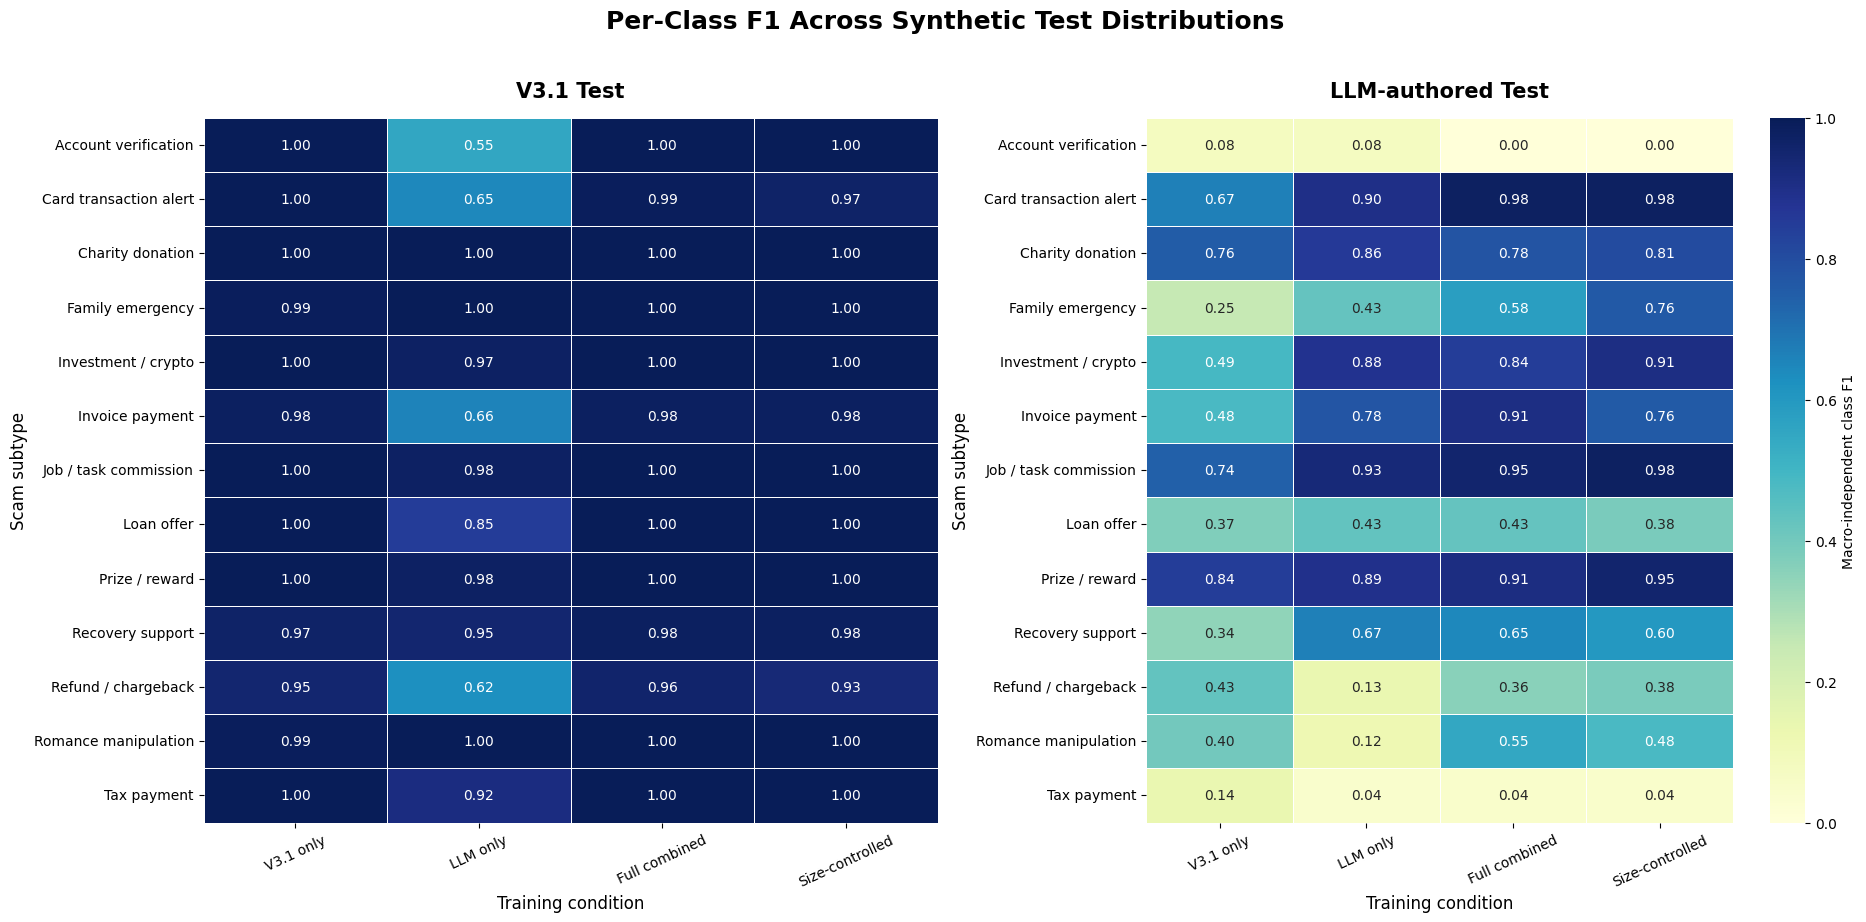

Saved figures:
PNG: /content/drive/MyDrive/financial-scam-analysis/outputs/distilbert_multilevel/analysis/subtype/subtype_per_class_f1_heatmap.png
PDF: /content/drive/MyDrive/financial-scam-analysis/outputs/distilbert_multilevel/analysis/subtype/subtype_per_class_f1_heatmap.pdf


In [24]:
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

# Consistent experiment and class ordering
experiment_labels = {
    "v31_only": "V3.1 only",
    "llm_only": "LLM only",
    "full_combined": "Full combined",
    "size_controlled_combined": "Size-controlled"
}

class_labels = [
    "Account verification",
    "Card transaction alert",
    "Charity donation",
    "Family emergency",
    "Investment / crypto",
    "Invoice payment",
    "Job / task commission",
    "Loan offer",
    "Prize / reward",
    "Recovery support",
    "Refund / chargeback",
    "Romance manipulation",
    "Tax payment"
]

fig, axes = plt.subplots(1, 2, figsize=(19, 9))

for ax, test_source, title in [
    (axes[0], "v31", "V3.1 Test"),
    (axes[1], "llm", "LLM-authored Test")
]:

    plot_df = (
        subtype_per_class_df[
            subtype_per_class_df["test_source"] == test_source
        ]
        .pivot(
            index="class",
            columns="experiment",
            values="f1_score"
        )
        .reindex(index=subtype_classes, columns=EXPERIMENT_ORDER)
    )

    plot_df.index = class_labels
    plot_df.columns = [
        experiment_labels[col] for col in plot_df.columns
    ]

    sns.heatmap(
        plot_df,
        ax=ax,
        annot=True,
        fmt=".2f",
        cmap="YlGnBu",
        vmin=0,
        vmax=1,
        linewidths=0.5,
        linecolor="white",
        cbar=(test_source == "llm"),
        cbar_kws={"label": "Macro-independent class F1"}
    )

    ax.set_title(title, fontsize=15, fontweight="bold", pad=15)
    ax.set_xlabel("Training condition", fontsize=12)
    ax.set_ylabel("Scam subtype", fontsize=12)
    ax.tick_params(axis="x", rotation=25, labelsize=10)
    ax.tick_params(axis="y", rotation=0, labelsize=10)

fig.suptitle(
    "Per-Class F1 Across Synthetic Test Distributions",
    fontsize=18,
    fontweight="bold",
    y=1.02
)

plt.tight_layout()

# Save research figures
figure_path = SUBTYPE_DIR / "subtype_per_class_f1_heatmap"

fig.savefig(
    f"{figure_path}.png",
    dpi=300,
    bbox_inches="tight"
)

fig.savefig(
    f"{figure_path}.pdf",
    bbox_inches="tight"
)

plt.show()
plt.close(fig)

print("Saved figures:")
print(f"PNG: {figure_path}.png")
print(f"PDF: {figure_path}.pdf")

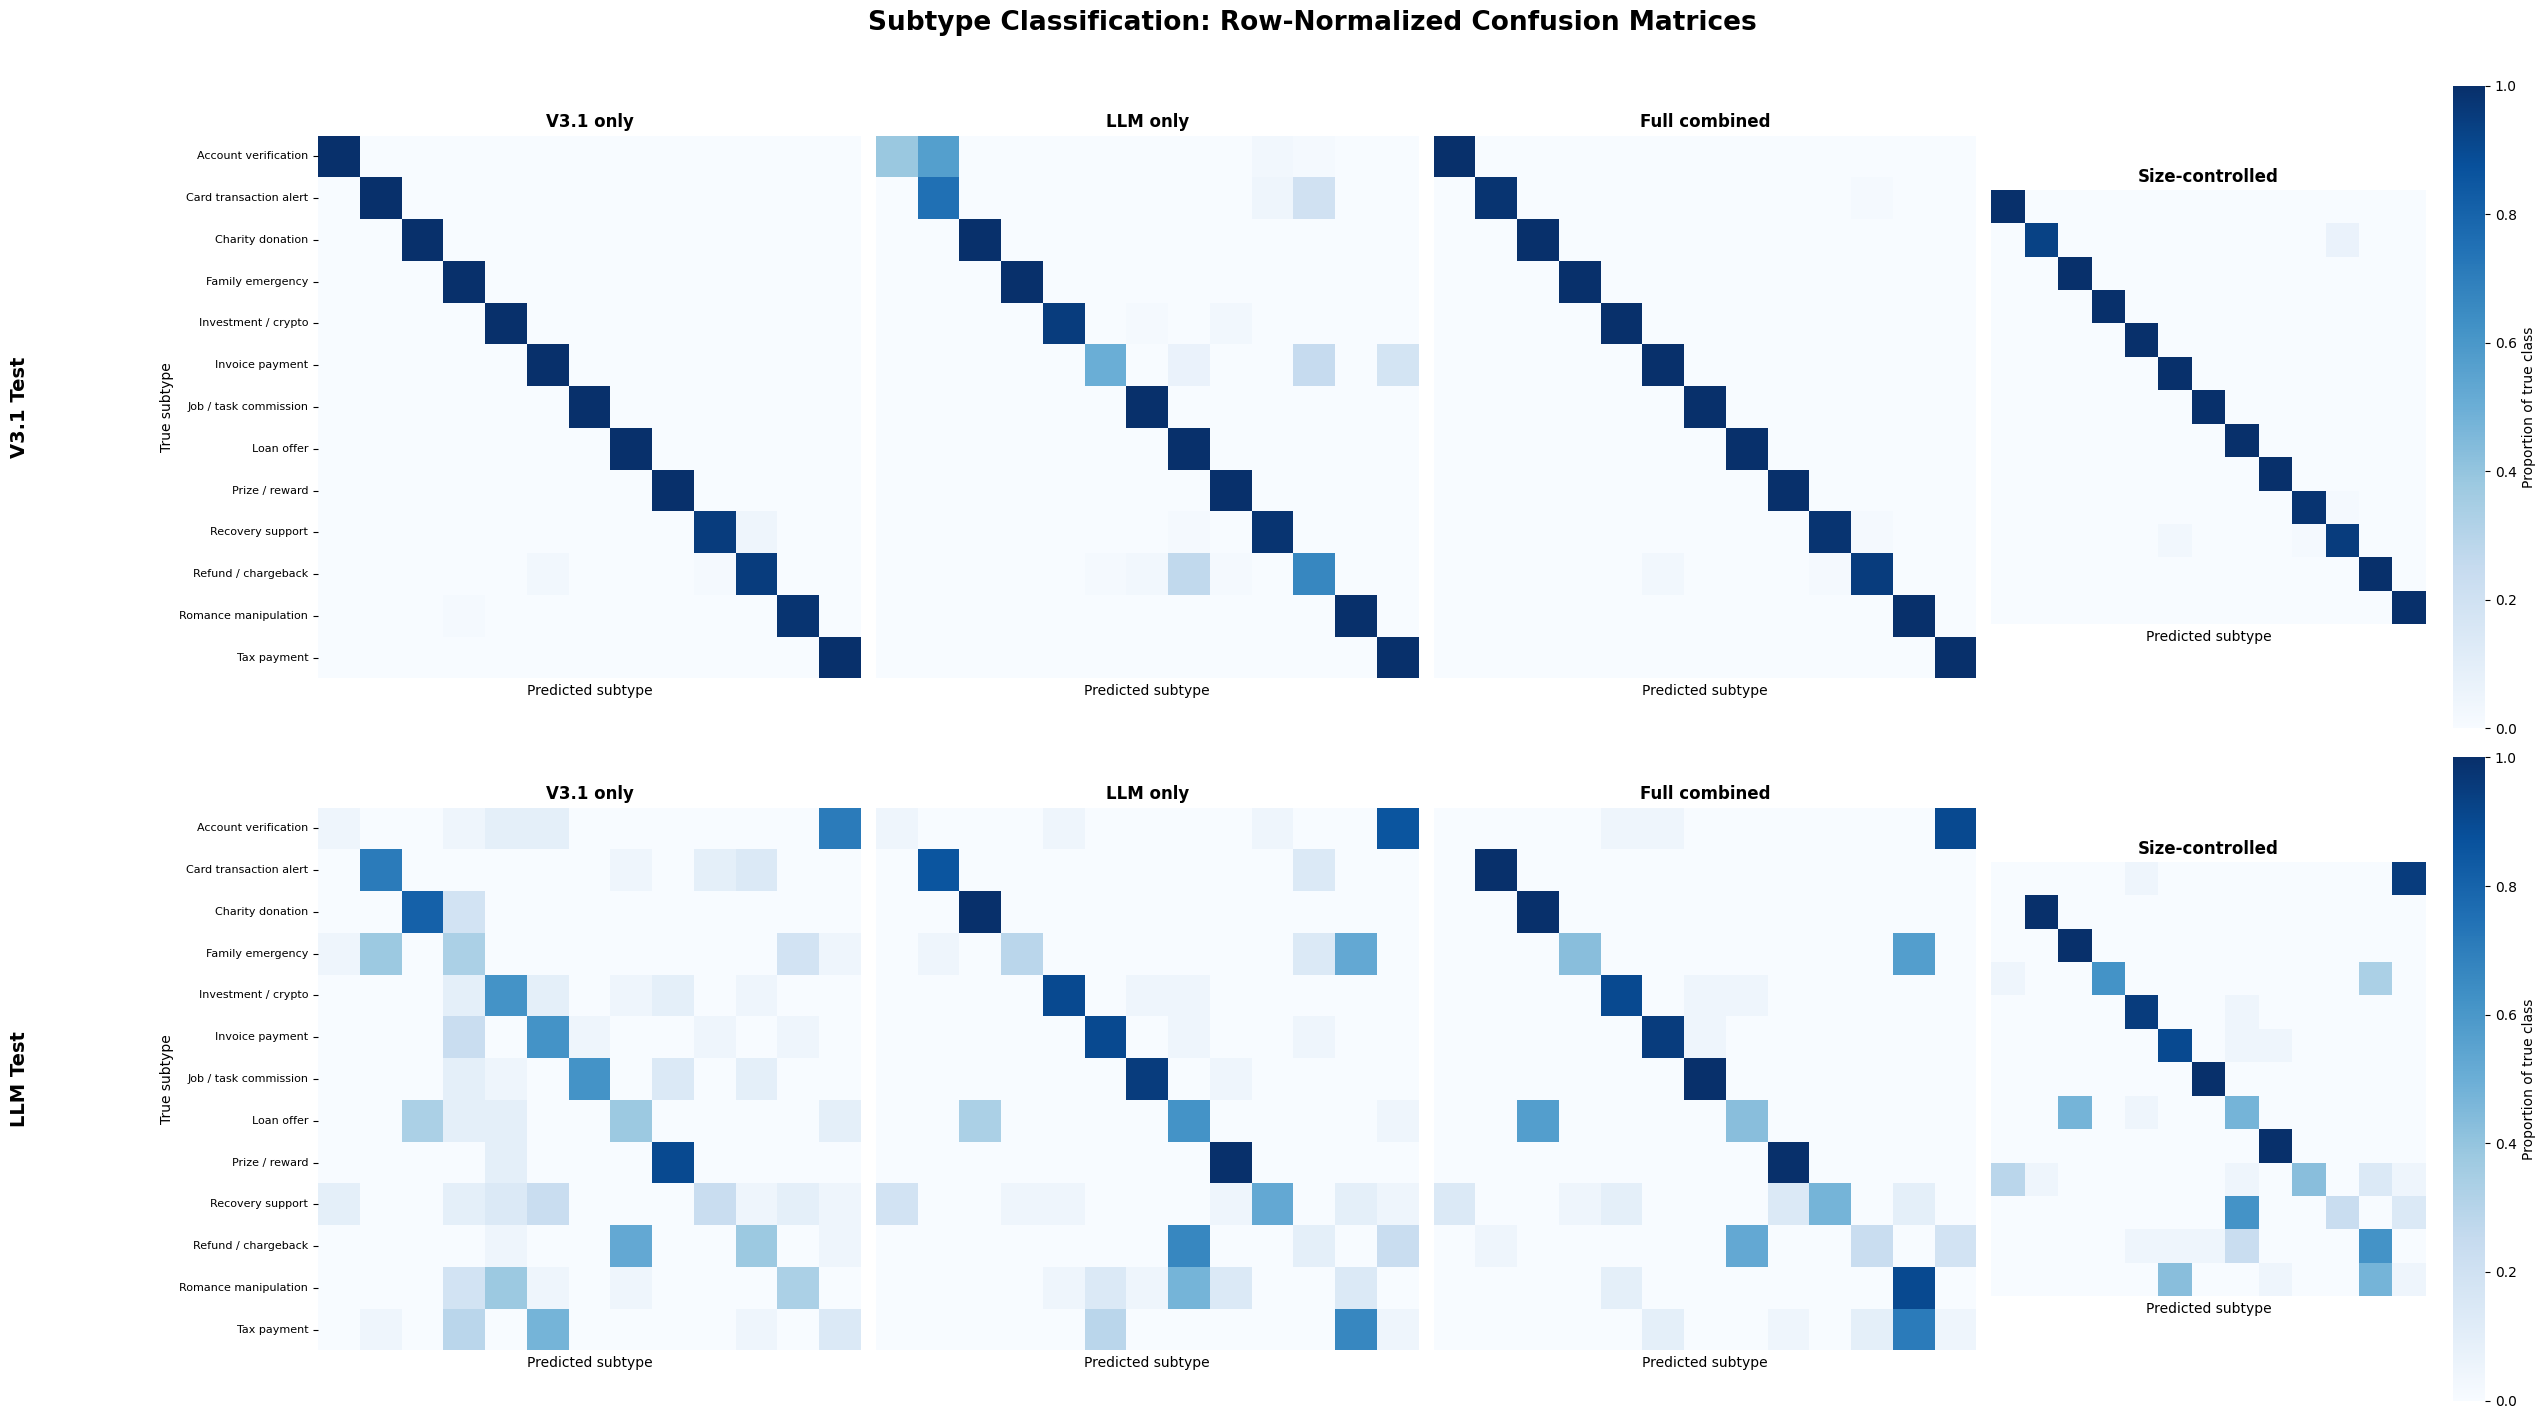

Saved:
PNG: /content/drive/MyDrive/financial-scam-analysis/outputs/distilbert_multilevel/analysis/subtype/subtype_confusion_matrices.png
PDF: /content/drive/MyDrive/financial-scam-analysis/outputs/distilbert_multilevel/analysis/subtype/subtype_confusion_matrices.pdf
CSV: /content/drive/MyDrive/financial-scam-analysis/outputs/distilbert_multilevel/analysis/subtype/subtype_confusion_matrix_data.csv
Total confusion matrices: 8


In [25]:
from sklearn.metrics import confusion_matrix

SUBTYPE_DIR.mkdir(parents=True, exist_ok=True)

fig, axes = plt.subplots(2, 4, figsize=(25, 14))

confusion_exports = []

for row_idx, test_source in enumerate(["v31", "llm"]):
    for col_idx, experiment in enumerate(EXPERIMENT_ORDER):

        ax = axes[row_idx, col_idx]

        subset = all_predictions_df[
            (all_predictions_df["task"] == "subtype")
            & (all_predictions_df["experiment"] == experiment)
            & (all_predictions_df["test_source"] == test_source)
        ].copy()

        y_true = subset["true_label"].values
        y_pred = subset["predicted_label"].values

        cm = confusion_matrix(
            y_true,
            y_pred,
            labels=subtype_classes
        )

        cm_normalized = np.divide(
            cm.astype(float),
            cm.sum(axis=1, keepdims=True),
            out=np.zeros_like(cm, dtype=float),
            where=cm.sum(axis=1, keepdims=True) != 0
        )

        # Export raw and normalized values
        for i, true_class in enumerate(subtype_classes):
            for j, predicted_class in enumerate(subtype_classes):
                confusion_exports.append({
                    "experiment": experiment,
                    "test_source": test_source,
                    "true_class": true_class,
                    "predicted_class": predicted_class,
                    "count": int(cm[i, j]),
                    "row_normalized": float(cm_normalized[i, j])
                })

        sns.heatmap(
            cm_normalized,
            ax=ax,
            cmap="Blues",
            vmin=0,
            vmax=1,
            square=True,
            cbar=(col_idx == 3),
            cbar_kws={"label": "Proportion of true class"},
            xticklabels=False,
            yticklabels=class_labels if col_idx == 0 else False
        )

        ax.set_title(
            f"{experiment_labels[experiment]}",
            fontsize=12,
            fontweight="bold"
        )

        ax.set_xlabel("Predicted subtype", fontsize=10)
        ax.set_ylabel(
            "True subtype" if col_idx == 0 else "",
            fontsize=10
        )

        ax.tick_params(axis="x", rotation=90, labelsize=8)
        ax.tick_params(axis="y", rotation=0, labelsize=8)

        # Show source label on the left
        if col_idx == 0:
            ax.text(
                -0.55, 0.5,
                "V3.1 Test" if test_source == "v31" else "LLM Test",
                transform=ax.transAxes,
                rotation=90,
                va="center",
                ha="center",
                fontsize=14,
                fontweight="bold"
            )

fig.suptitle(
    "Subtype Classification: Row-Normalized Confusion Matrices",
    fontsize=19,
    fontweight="bold",
    y=1.01
)

plt.tight_layout()

figure_path = SUBTYPE_DIR / "subtype_confusion_matrices"

fig.savefig(
    f"{figure_path}.png",
    dpi=300,
    bbox_inches="tight"
)

fig.savefig(
    f"{figure_path}.pdf",
    bbox_inches="tight"
)

plt.show()
plt.close(fig)

# Save confusion matrix data
confusion_df = pd.DataFrame(confusion_exports)

confusion_df.to_csv(
    SUBTYPE_DIR / "subtype_confusion_matrix_data.csv",
    index=False
)

print("Saved:")
print(f"PNG: {figure_path}.png")
print(f"PDF: {figure_path}.pdf")
print(f"CSV: {SUBTYPE_DIR / 'subtype_confusion_matrix_data.csv'}")
print(f"Total confusion matrices: {len(confusion_exports) // (len(subtype_classes) ** 2)}")

In [26]:
INTENT_DIR = OUTPUT_DIR / "analysis" / "intent"
INTENT_DIR.mkdir(parents=True, exist_ok=True)

intent_classes = LABEL_MAPPINGS["intent"]

intent_reports = []

for experiment in EXPERIMENT_ORDER:
    for test_source in ["v31", "llm"]:

        subset = all_predictions_df[
            (all_predictions_df["task"] == "intent")
            & (all_predictions_df["experiment"] == experiment)
            & (all_predictions_df["test_source"] == test_source)
        ].copy()

        y_true = subset["true_label"].values
        y_pred = subset["predicted_label"].values

        report = classification_report(
            y_true,
            y_pred,
            labels=intent_classes,
            target_names=intent_classes,
            output_dict=True,
            zero_division=0
        )

        for class_name in intent_classes:
            metrics = report[class_name]

            intent_reports.append({
                "task": "intent",
                "experiment": experiment,
                "test_source": test_source,
                "class": class_name,
                "precision": metrics["precision"],
                "recall": metrics["recall"],
                "f1_score": metrics["f1-score"],
                "support": int(metrics["support"])
            })

intent_per_class_df = pd.DataFrame(intent_reports)

intent_per_class_df.to_csv(
    INTENT_DIR / "intent_per_class_metrics.csv",
    index=False
)

with open(
    INTENT_DIR / "intent_per_class_metrics.json",
    "w",
    encoding="utf-8"
) as f:
    json.dump(
        intent_reports,
        f,
        indent=2,
        ensure_ascii=False
    )

print("=" * 90)
print("FRAUDULENT INTENT: PER-CLASS PERFORMANCE")
print("=" * 90)

for test_source in ["v31", "llm"]:

    print(f"\n{'V3.1 TEST' if test_source == 'v31' else 'LLM TEST'}")
    print("-" * 90)

    display(
        intent_per_class_df[
            intent_per_class_df["test_source"] == test_source
        ].pivot(
            index="class",
            columns="experiment",
            values="f1_score"
        ).reindex(intent_classes).round(4)
    )

print("\nSaved detailed reports to:", INTENT_DIR)

FRAUDULENT INTENT: PER-CLASS PERFORMANCE

V3.1 TEST
------------------------------------------------------------------------------------------


experiment,full_combined,llm_only,size_controlled_combined,v31_only
class,,,,
gain_account_or_device_access,0.9916,0.7475,0.9916,1.0000
induce_fraudulent_investment,1.0000,0.7547,1.0000,1.0000
induce_payment_or_transfer,1.0000,0.9637,1.0000,1.0000
obtain_credentials_or_codes,0.9961,0.8906,0.9961,0.9961
obtain_personal_or_financial_information,1.0000,0.9297,1.0000,0.9970



LLM TEST
------------------------------------------------------------------------------------------


experiment,full_combined,llm_only,size_controlled_combined,v31_only
class,,,,
gain_account_or_device_access,0.3871,0.3529,0.4375,0.3704
induce_fraudulent_investment,0.8000,0.6829,0.5946,0.5641
induce_payment_or_transfer,0.8498,0.8487,0.8197,0.7583
obtain_credentials_or_codes,0.7636,0.7523,0.7573,0.5677
obtain_personal_or_financial_information,0.7874,0.7419,0.7846,0.7018



Saved detailed reports to: /content/drive/MyDrive/financial-scam-analysis/outputs/distilbert_multilevel/analysis/intent


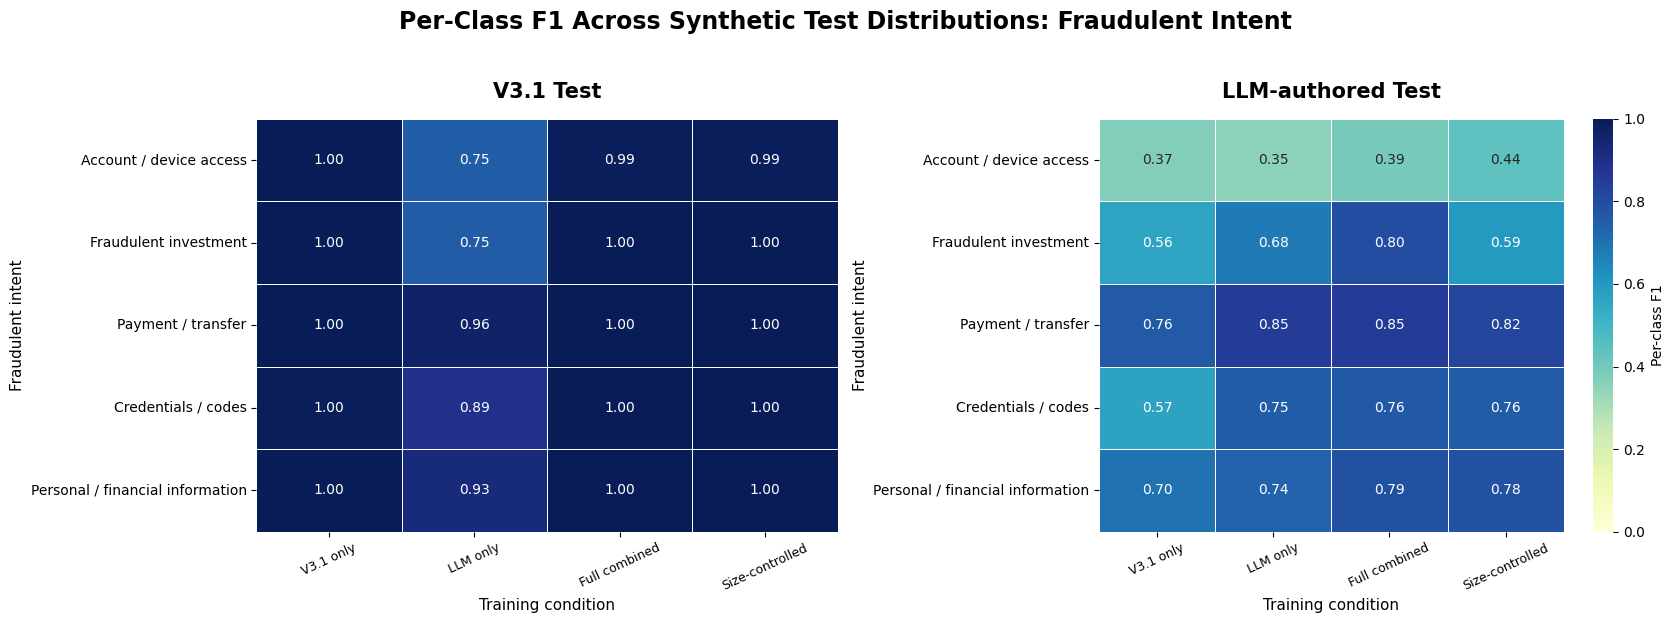

Saved:
PNG: /content/drive/MyDrive/financial-scam-analysis/outputs/distilbert_multilevel/analysis/intent/intent_per_class_f1_heatmap.png
PDF: /content/drive/MyDrive/financial-scam-analysis/outputs/distilbert_multilevel/analysis/intent/intent_per_class_f1_heatmap.pdf


In [27]:
intent_labels = [
    "Account / device access",
    "Fraudulent investment",
    "Payment / transfer",
    "Credentials / codes",
    "Personal / financial information"
]

fig, axes = plt.subplots(1, 2, figsize=(17, 6))

for ax, test_source, title in [
    (axes[0], "v31", "V3.1 Test"),
    (axes[1], "llm", "LLM-authored Test")
]:

    plot_df = (
        intent_per_class_df[
            intent_per_class_df["test_source"] == test_source
        ]
        .pivot(
            index="class",
            columns="experiment",
            values="f1_score"
        )
        .reindex(index=intent_classes, columns=EXPERIMENT_ORDER)
    )

    plot_df.index = intent_labels
    plot_df.columns = [
        experiment_labels[col] for col in plot_df.columns
    ]

    sns.heatmap(
        plot_df,
        ax=ax,
        annot=True,
        fmt=".2f",
        cmap="YlGnBu",
        vmin=0,
        vmax=1,
        linewidths=0.5,
        linecolor="white",
        cbar=(test_source == "llm"),
        cbar_kws={"label": "Per-class F1"}
    )

    ax.set_title(title, fontsize=15, fontweight="bold", pad=15)
    ax.set_xlabel("Training condition", fontsize=11)
    ax.set_ylabel("Fraudulent intent", fontsize=11)
    ax.tick_params(axis="x", rotation=25, labelsize=9)
    ax.tick_params(axis="y", rotation=0, labelsize=10)

fig.suptitle(
    "Per-Class F1 Across Synthetic Test Distributions: Fraudulent Intent",
    fontsize=17,
    fontweight="bold",
    y=1.03
)

plt.tight_layout()

figure_path = INTENT_DIR / "intent_per_class_f1_heatmap"

fig.savefig(
    f"{figure_path}.png",
    dpi=300,
    bbox_inches="tight"
)

fig.savefig(
    f"{figure_path}.pdf",
    bbox_inches="tight"
)

plt.show()
plt.close(fig)

print("Saved:")
print(f"PNG: {figure_path}.png")
print(f"PDF: {figure_path}.pdf")

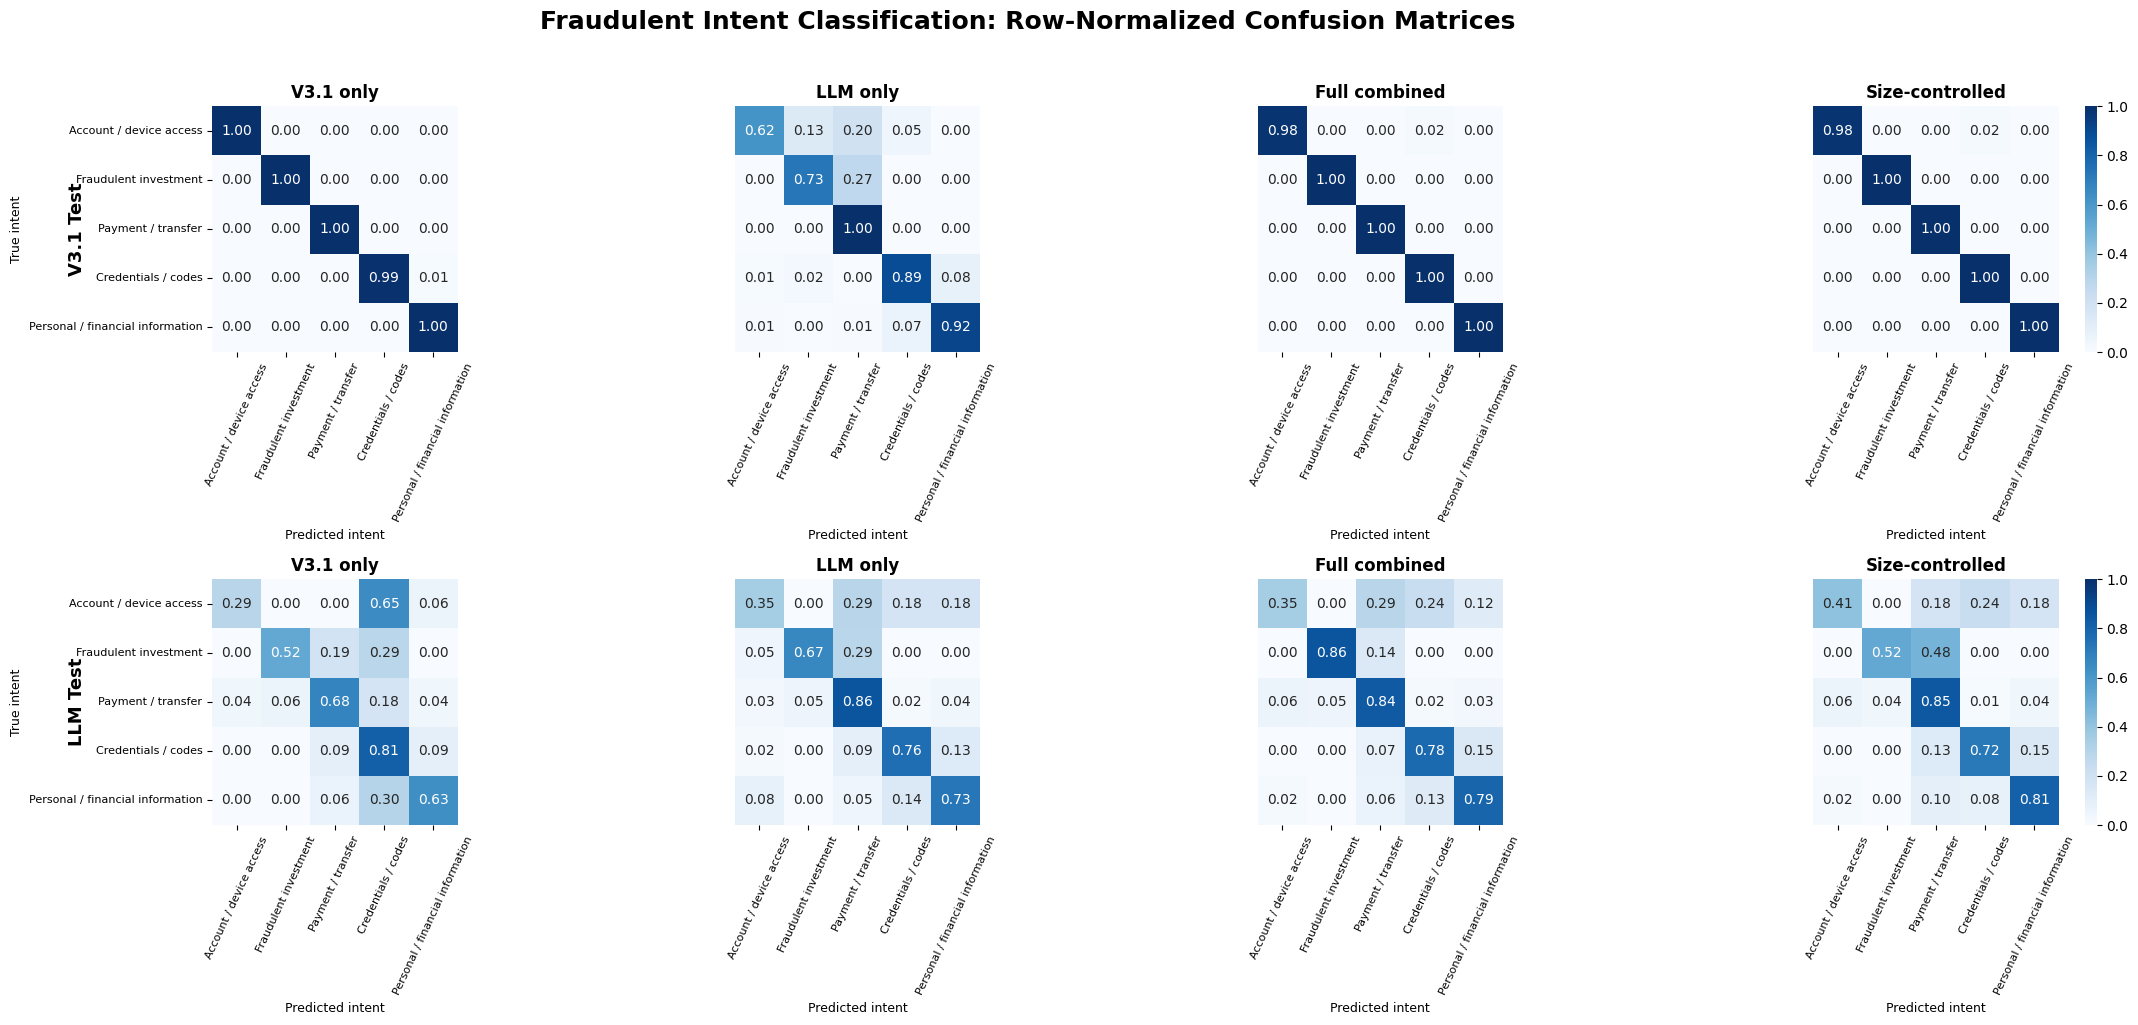

Saved:
PNG: /content/drive/MyDrive/financial-scam-analysis/outputs/distilbert_multilevel/analysis/intent/intent_confusion_matrices.png
PDF: /content/drive/MyDrive/financial-scam-analysis/outputs/distilbert_multilevel/analysis/intent/intent_confusion_matrices.pdf


In [28]:
from sklearn.metrics import confusion_matrix

fig, axes = plt.subplots(2, 4, figsize=(23, 10))

for row_idx, test_source in enumerate(["v31", "llm"]):
    for col_idx, experiment in enumerate(EXPERIMENT_ORDER):

        ax = axes[row_idx, col_idx]

        subset = all_predictions_df[
            (all_predictions_df["task"] == "intent")
            & (all_predictions_df["experiment"] == experiment)
            & (all_predictions_df["test_source"] == test_source)
        ].copy()

        cm = confusion_matrix(
            subset["true_label"],
            subset["predicted_label"],
            labels=intent_classes
        )

        cm_normalized = np.divide(
            cm.astype(float),
            cm.sum(axis=1, keepdims=True),
            out=np.zeros_like(cm, dtype=float),
            where=cm.sum(axis=1, keepdims=True) != 0
        )

        sns.heatmap(
            cm_normalized,
            ax=ax,
            annot=True,
            fmt=".2f",
            cmap="Blues",
            vmin=0,
            vmax=1,
            square=True,
            cbar=(col_idx == 3),
            xticklabels=intent_labels,
            yticklabels=intent_labels if col_idx == 0 else False
        )

        ax.set_title(
            experiment_labels[experiment],
            fontsize=12,
            fontweight="bold"
        )
        ax.set_xlabel("Predicted intent", fontsize=9)
        ax.set_ylabel(
            "True intent" if col_idx == 0 else "",
            fontsize=9
        )
        ax.tick_params(axis="x", rotation=65, labelsize=8)
        ax.tick_params(axis="y", rotation=0, labelsize=8)

        if col_idx == 0:
            ax.text(
                -0.55, 0.5,
                "V3.1 Test" if test_source == "v31" else "LLM Test",
                transform=ax.transAxes,
                rotation=90,
                va="center",
                ha="center",
                fontsize=13,
                fontweight="bold"
            )

fig.suptitle(
    "Fraudulent Intent Classification: Row-Normalized Confusion Matrices",
    fontsize=18,
    fontweight="bold",
    y=1.02
)

plt.tight_layout()

figure_path = INTENT_DIR / "intent_confusion_matrices"

fig.savefig(
    f"{figure_path}.png",
    dpi=300,
    bbox_inches="tight"
)

fig.savefig(
    f"{figure_path}.pdf",
    bbox_inches="tight"
)

plt.show()
plt.close(fig)

print("Saved:")
print(f"PNG: {figure_path}.png")
print(f"PDF: {figure_path}.pdf")

In [29]:
TACTICS_DIR = OUTPUT_DIR / "analysis" / "tactics"
TACTICS_DIR.mkdir(parents=True, exist_ok=True)

tactic_classes = LABEL_MAPPINGS["tactics"]

tactic_reports = []

for experiment in EXPERIMENT_ORDER:
    for test_source in ["v31", "llm"]:

        subset = all_predictions_df[
            (all_predictions_df["task"] == "tactics")
            & (all_predictions_df["experiment"] == experiment)
            & (all_predictions_df["test_source"] == test_source)
        ].copy()

        y_true = np.array([
            [int(tactic in json.loads(value)) for tactic in tactic_classes]
            for value in subset["true_tactics"]
        ])

        y_pred = np.array([
            [int(tactic in json.loads(value)) for tactic in tactic_classes]
            for value in subset["predicted_tactics"]
        ])

        report = classification_report(
            y_true,
            y_pred,
            target_names=tactic_classes,
            output_dict=True,
            zero_division=0
        )

        for tactic in tactic_classes:
            metrics = report[tactic]

            tactic_reports.append({
                "task": "tactics",
                "experiment": experiment,
                "test_source": test_source,
                "tactic": tactic,
                "precision": metrics["precision"],
                "recall": metrics["recall"],
                "f1_score": metrics["f1-score"],
                "support": int(metrics["support"])
            })

tactic_per_class_df = pd.DataFrame(tactic_reports)

tactic_per_class_df.to_csv(
    TACTICS_DIR / "tactic_per_class_metrics.csv",
    index=False
)

with open(
    TACTICS_DIR / "tactic_per_class_metrics.json",
    "w",
    encoding="utf-8"
) as f:
    json.dump(
        tactic_reports,
        f,
        indent=2,
        ensure_ascii=False
    )

print("=" * 95)
print("SOCIAL-ENGINEERING TACTICS: PER-TACTIC PERFORMANCE")
print("=" * 95)

for test_source in ["v31", "llm"]:

    print(f"\n{'V3.1 TEST' if test_source == 'v31' else 'LLM TEST'}")
    print("-" * 95)

    display(
        tactic_per_class_df[
            tactic_per_class_df["test_source"] == test_source
        ].pivot(
            index="tactic",
            columns="experiment",
            values="f1_score"
        ).reindex(tactic_classes).round(4)
    )

print("\nSaved detailed reports to:", TACTICS_DIR)

SOCIAL-ENGINEERING TACTICS: PER-TACTIC PERFORMANCE

V3.1 TEST
-----------------------------------------------------------------------------------------------


experiment,full_combined,llm_only,size_controlled_combined,v31_only
tactic,,,,
authority_impersonation,1.0,0.5572,1.0000,1.0
emotional_manipulation,1.0,0.5514,1.0000,1.0
false_legitimacy,1.0,0.5184,0.9890,1.0
fear_or_threat,1.0,0.5022,0.9920,1.0
reward_or_benefit,1.0,0.5503,0.9871,1.0
scarcity,1.0,0.0000,1.0000,1.0
secrecy,1.0,0.0000,1.0000,1.0
trust_exploitation,1.0,0.5200,1.0000,1.0
urgency,1.0,0.5653,1.0000,1.0



LLM TEST
-----------------------------------------------------------------------------------------------


experiment,full_combined,llm_only,size_controlled_combined,v31_only
tactic,,,,
authority_impersonation,0.7226,0.7771,0.7215,0.0000
emotional_manipulation,0.8911,0.9027,0.8041,0.0357
false_legitimacy,0.8213,0.8049,0.7903,0.3041
fear_or_threat,0.8214,0.8171,0.7692,0.2222
reward_or_benefit,0.7905,0.7876,0.7576,0.2778
scarcity,0.3333,0.0000,0.2857,0.1633
secrecy,0.0000,0.0000,0.0000,0.0000
trust_exploitation,0.8077,0.8129,0.7682,0.4483
urgency,0.8997,0.8442,0.9043,0.5224



Saved detailed reports to: /content/drive/MyDrive/financial-scam-analysis/outputs/distilbert_multilevel/analysis/tactics


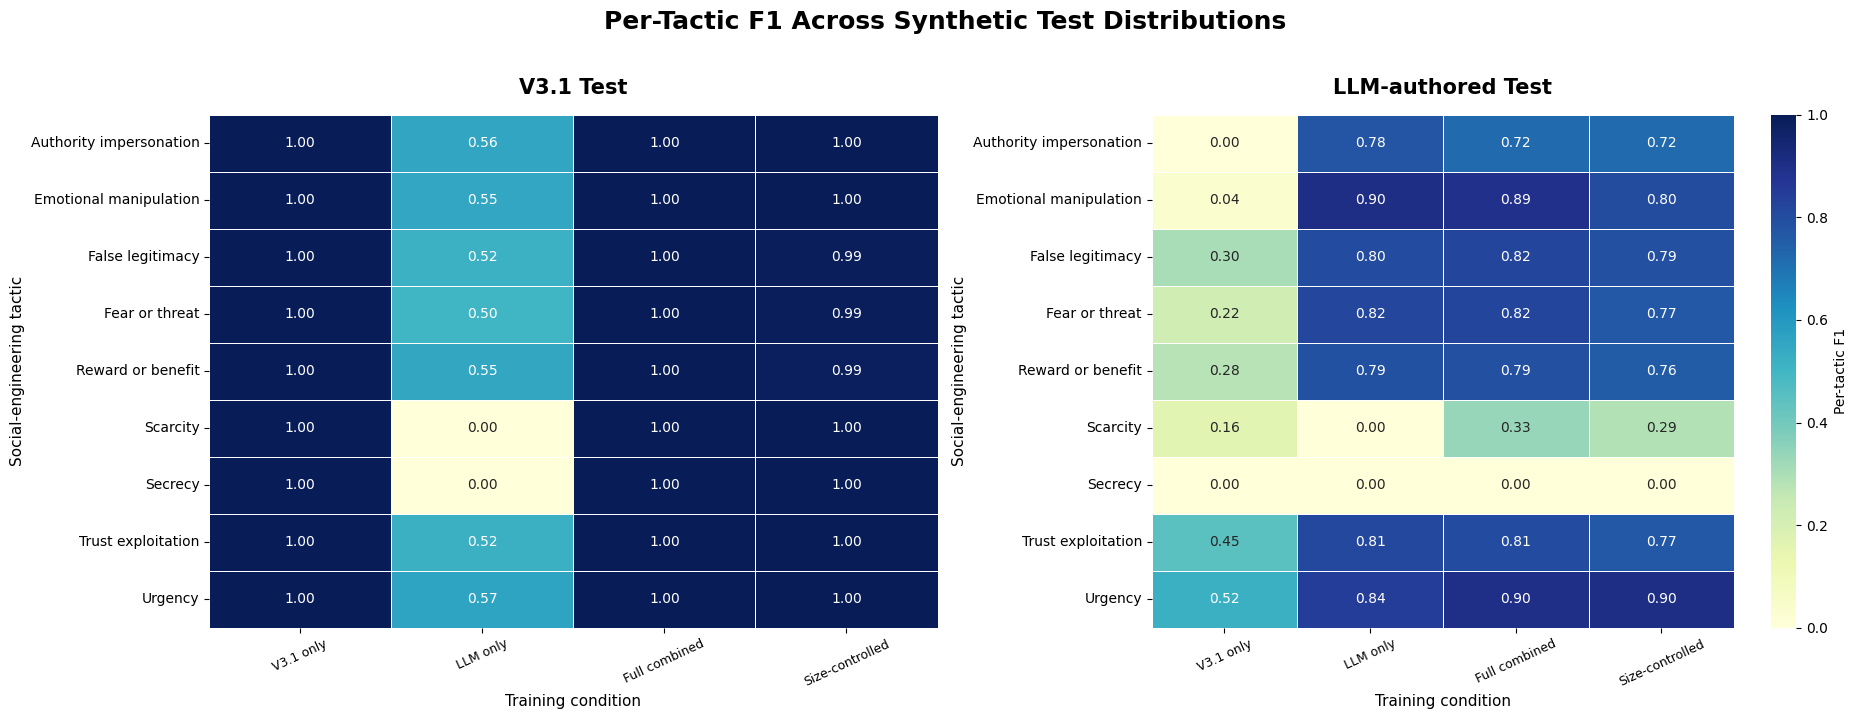

Saved:
PNG: /content/drive/MyDrive/financial-scam-analysis/outputs/distilbert_multilevel/analysis/tactics/tactics_per_class_f1_heatmap.png
PDF: /content/drive/MyDrive/financial-scam-analysis/outputs/distilbert_multilevel/analysis/tactics/tactics_per_class_f1_heatmap.pdf


In [30]:
tactic_labels = [
    "Authority impersonation",
    "Emotional manipulation",
    "False legitimacy",
    "Fear or threat",
    "Reward or benefit",
    "Scarcity",
    "Secrecy",
    "Trust exploitation",
    "Urgency"
]

fig, axes = plt.subplots(1, 2, figsize=(19, 7))

for ax, test_source, title in [
    (axes[0], "v31", "V3.1 Test"),
    (axes[1], "llm", "LLM-authored Test")
]:

    plot_df = (
        tactic_per_class_df[
            tactic_per_class_df["test_source"] == test_source
        ]
        .pivot(
            index="tactic",
            columns="experiment",
            values="f1_score"
        )
        .reindex(index=tactic_classes, columns=EXPERIMENT_ORDER)
    )

    plot_df.index = tactic_labels
    plot_df.columns = [
        experiment_labels[col] for col in plot_df.columns
    ]

    sns.heatmap(
        plot_df,
        ax=ax,
        annot=True,
        fmt=".2f",
        cmap="YlGnBu",
        vmin=0,
        vmax=1,
        linewidths=0.5,
        linecolor="white",
        cbar=(test_source == "llm"),
        cbar_kws={"label": "Per-tactic F1"}
    )

    ax.set_title(title, fontsize=15, fontweight="bold", pad=15)
    ax.set_xlabel("Training condition", fontsize=11)
    ax.set_ylabel("Social-engineering tactic", fontsize=11)
    ax.tick_params(axis="x", rotation=25, labelsize=9)
    ax.tick_params(axis="y", rotation=0, labelsize=10)

fig.suptitle(
    "Per-Tactic F1 Across Synthetic Test Distributions",
    fontsize=18,
    fontweight="bold",
    y=1.02
)

plt.tight_layout()

figure_path = TACTICS_DIR / "tactics_per_class_f1_heatmap"

fig.savefig(
    f"{figure_path}.png",
    dpi=300,
    bbox_inches="tight"
)

fig.savefig(
    f"{figure_path}.pdf",
    bbox_inches="tight"
)

plt.show()
plt.close(fig)

print("Saved:")
print(f"PNG: {figure_path}.png")
print(f"PDF: {figure_path}.pdf")

In [31]:
tactic_count_reports = []

for experiment in EXPERIMENT_ORDER:
    for test_source in ["v31", "llm"]:

        subset = all_predictions_df[
            (all_predictions_df["task"] == "tactics")
            & (all_predictions_df["experiment"] == experiment)
            & (all_predictions_df["test_source"] == test_source)
        ].copy()

        y_true = np.array([
            [int(t in json.loads(v)) for t in tactic_classes]
            for v in subset["true_tactics"]
        ])

        y_pred = np.array([
            [int(t in json.loads(v)) for t in tactic_classes]
            for v in subset["predicted_tactics"]
        ])

        for i, tactic in enumerate(tactic_classes):

            tp = int(np.sum((y_true[:, i] == 1) & (y_pred[:, i] == 1)))
            fp = int(np.sum((y_true[:, i] == 0) & (y_pred[:, i] == 1)))
            fn = int(np.sum((y_true[:, i] == 1) & (y_pred[:, i] == 0)))
            tn = int(np.sum((y_true[:, i] == 0) & (y_pred[:, i] == 0)))

            precision = tp / (tp + fp) if tp + fp else 0.0
            recall = tp / (tp + fn) if tp + fn else 0.0
            f1 = (
                2 * precision * recall / (precision + recall)
                if precision + recall else 0.0
            )

            tactic_count_reports.append({
                "experiment": experiment,
                "test_source": test_source,
                "tactic": tactic,
                "support": tp + fn,
                "predicted_positive": tp + fp,
                "true_positive": tp,
                "false_positive": fp,
                "false_negative": fn,
                "true_negative": tn,
                "precision": precision,
                "recall": recall,
                "f1_score": f1
            })

tactic_support_df = pd.DataFrame(tactic_count_reports)

tactic_support_df.to_csv(
    TACTICS_DIR / "tactic_support_and_error_counts.csv",
    index=False
)

print("=" * 100)
print("TACTIC SUPPORT AND PREDICTION AUDIT")
print("=" * 100)

for test_source in ["v31", "llm"]:

    print(f"\n{'V3.1 TEST' if test_source == 'v31' else 'LLM TEST'}")
    print("-" * 100)

    display(
        tactic_support_df[
            (tactic_support_df["test_source"] == test_source)
            & (tactic_support_df["experiment"] == "full_combined")
        ][[
            "tactic",
            "support",
            "predicted_positive",
            "true_positive",
            "false_positive",
            "false_negative",
            "precision",
            "recall",
            "f1_score"
        ]].set_index("tactic").round(4)
    )

print("\nSaved:", TACTICS_DIR / "tactic_support_and_error_counts.csv")

TACTIC SUPPORT AND PREDICTION AUDIT

V3.1 TEST
----------------------------------------------------------------------------------------------------


,support,predicted_positive,true_positive,false_positive,false_negative,precision,recall,f1_score
tactic,,,,,,,,
authority_impersonation,110,110,110,0,0,1.0,1.0,1.0
emotional_manipulation,72,72,72,0,0,1.0,1.0,1.0
false_legitimacy,183,183,183,0,0,1.0,1.0,1.0
fear_or_threat,63,63,63,0,0,1.0,1.0,1.0
reward_or_benefit,118,118,118,0,0,1.0,1.0,1.0
scarcity,77,77,77,0,0,1.0,1.0,1.0
secrecy,82,82,82,0,0,1.0,1.0,1.0
trust_exploitation,81,81,81,0,0,1.0,1.0,1.0
urgency,214,214,214,0,0,1.0,1.0,1.0



LLM TEST
----------------------------------------------------------------------------------------------------


,support,predicted_positive,true_positive,false_positive,false_negative,precision,recall,f1_score
tactic,,,,,,,,
authority_impersonation,76,79,56,23,20,0.7089,0.7368,0.7226
emotional_manipulation,55,46,45,1,10,0.9783,0.8182,0.8911
false_legitimacy,174,201,154,47,20,0.7662,0.8851,0.8213
fear_or_threat,87,81,69,12,18,0.8519,0.7931,0.8214
reward_or_benefit,118,92,83,9,35,0.9022,0.7034,0.7905
scarcity,41,13,9,4,32,0.6923,0.2195,0.3333
secrecy,6,0,0,0,6,0.0000,0.0000,0.0000
trust_exploitation,85,71,63,8,22,0.8873,0.7412,0.8077
urgency,173,176,157,19,16,0.8920,0.9075,0.8997



Saved: /content/drive/MyDrive/financial-scam-analysis/outputs/distilbert_multilevel/analysis/tactics/tactic_support_and_error_counts.csv


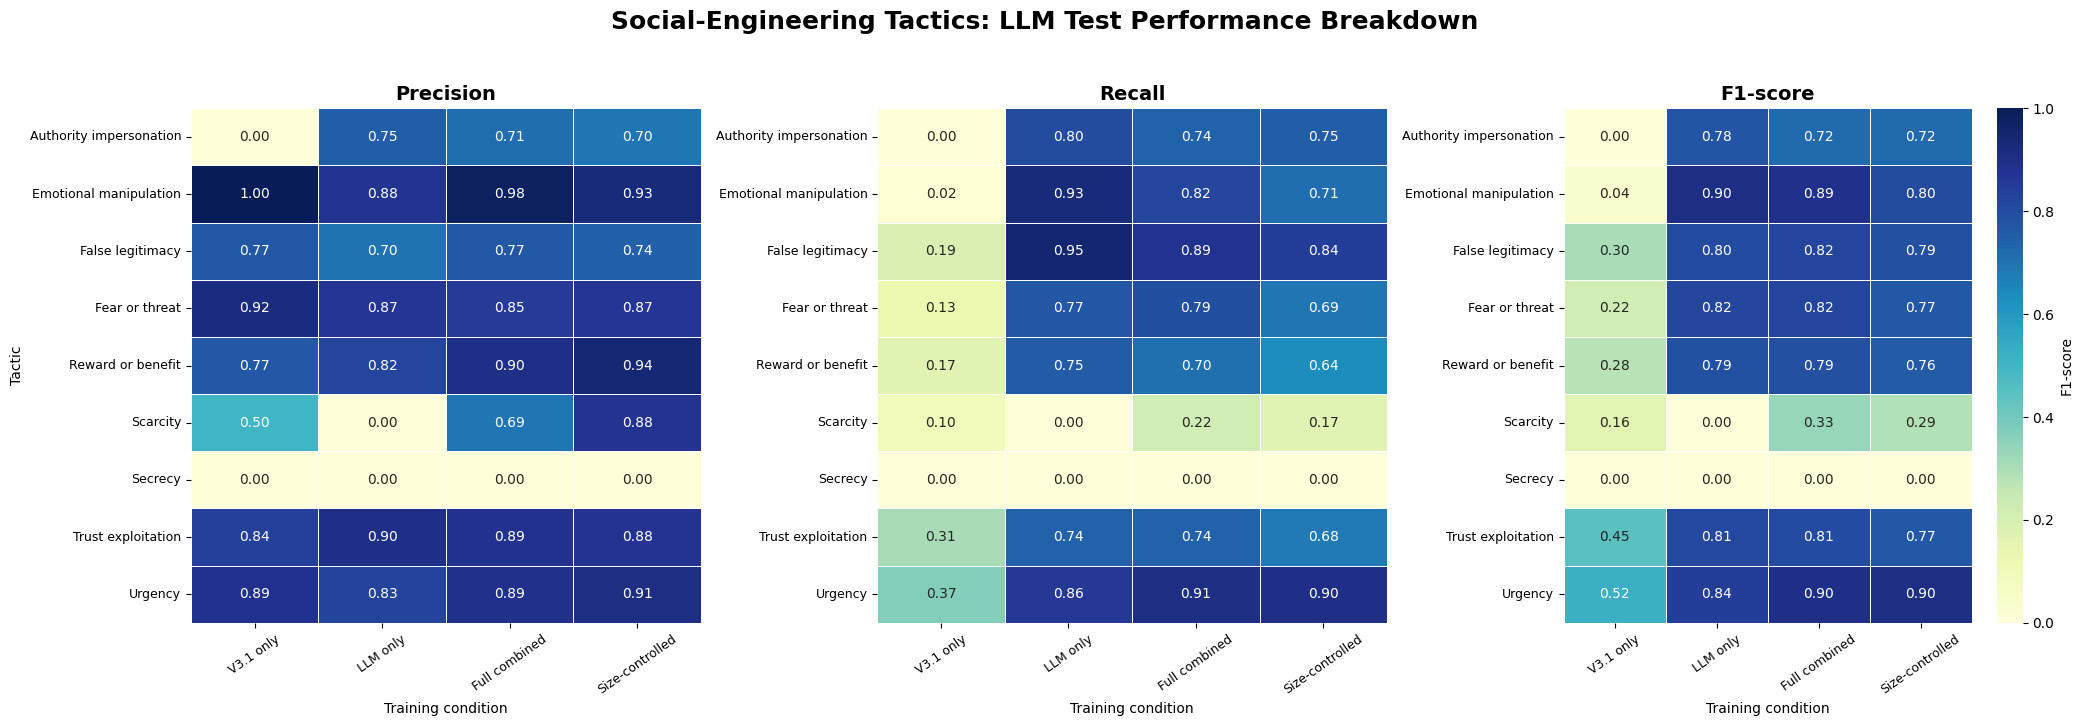

Saved:
PNG: /content/drive/MyDrive/financial-scam-analysis/outputs/distilbert_multilevel/analysis/tactics/tactics_llm_precision_recall_f1.png
PDF: /content/drive/MyDrive/financial-scam-analysis/outputs/distilbert_multilevel/analysis/tactics/tactics_llm_precision_recall_f1.pdf


In [32]:
# Prepare LLM test metrics for all training conditions
llm_tactic_metrics = tactic_support_df[
    tactic_support_df["test_source"] == "llm"
].copy()

metric_names = ["precision", "recall", "f1_score"]
metric_labels = ["Precision", "Recall", "F1-score"]

fig, axes = plt.subplots(1, 3, figsize=(21, 7))

for ax, metric, metric_label in zip(axes, metric_names, metric_labels):

    plot_df = (
        llm_tactic_metrics.pivot(
            index="tactic",
            columns="experiment",
            values=metric
        )
        .reindex(index=tactic_classes, columns=EXPERIMENT_ORDER)
    )

    plot_df.index = tactic_labels
    plot_df.columns = [
        experiment_labels[col] for col in plot_df.columns
    ]

    sns.heatmap(
        plot_df,
        ax=ax,
        annot=True,
        fmt=".2f",
        cmap="YlGnBu",
        vmin=0,
        vmax=1,
        linewidths=0.5,
        linecolor="white",
        cbar=(metric == "f1_score"),
        cbar_kws={"label": metric_label}
    )

    ax.set_title(metric_label, fontsize=14, fontweight="bold")
    ax.set_xlabel("Training condition", fontsize=10)
    ax.set_ylabel("Tactic" if metric == "precision" else "")
    ax.tick_params(axis="x", rotation=35, labelsize=9)
    ax.tick_params(axis="y", rotation=0, labelsize=9)

fig.suptitle(
    "Social-Engineering Tactics: LLM Test Performance Breakdown",
    fontsize=18,
    fontweight="bold",
    y=1.03
)

plt.tight_layout()

figure_path = TACTICS_DIR / "tactics_llm_precision_recall_f1"

fig.savefig(
    f"{figure_path}.png",
    dpi=300,
    bbox_inches="tight"
)

fig.savefig(
    f"{figure_path}.pdf",
    bbox_inches="tight"
)

plt.show()
plt.close(fig)

print("Saved:")
print(f"PNG: {figure_path}.png")
print(f"PDF: {figure_path}.pdf")

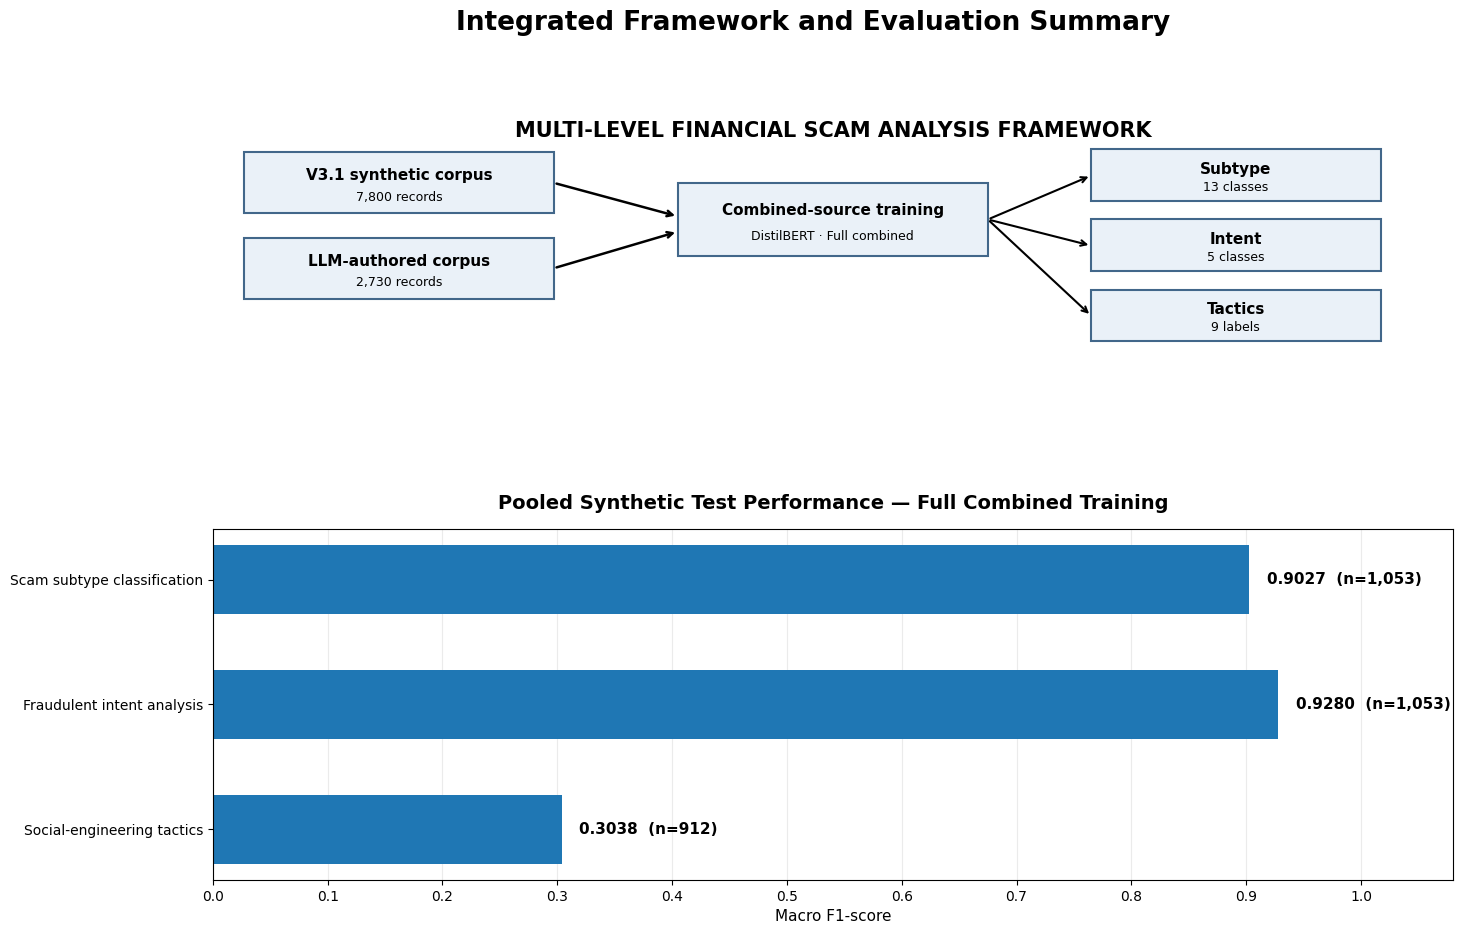

Phase 1 figure saved:
PNG: /content/drive/MyDrive/financial-scam-analysis/outputs/distilbert_multilevel/analysis/phase1_summary/phase1_integrated_framework_performance.png
PDF: /content/drive/MyDrive/financial-scam-analysis/outputs/distilbert_multilevel/analysis/phase1_summary/phase1_integrated_framework_performance.pdf


In [34]:
# Retrieve the full-combined pooled test metrics
phase1_results = (
    pooled_metrics_df[
        pooled_metrics_df["experiment"] == "full_combined"
    ]
    .set_index("task")
)

task_order = ["subtype", "intent", "tactics"]
task_names = [
    "Scam subtype classification",
    "Fraudulent intent analysis",
    "Social-engineering tactics"
]

scores = [
    phase1_results.loc[task, "macro_f1"]
    for task in task_order
]

test_counts = [
    int(phase1_results.loc[task, "test_records"])
    for task in task_order
]

fig = plt.figure(figsize=(16, 10))
gs = fig.add_gridspec(
    2, 1,
    height_ratios=[1, 1.15],
    hspace=0.35
)

# --------------------------------------------------
# TOP: Integrated framework architecture
# --------------------------------------------------
ax1 = fig.add_subplot(gs[0])
ax1.set_xlim(0, 12)
ax1.set_ylim(0, 5)
ax1.axis("off")

def draw_box(ax, x, y, width, height, title, subtitle):
    rect = plt.Rectangle(
        (x, y), width, height,
        facecolor="#eaf1f8",
        edgecolor="#42678a",
        linewidth=1.5,
        transform=ax.transData
    )
    ax.add_patch(rect)
    ax.text(
        x + width / 2, y + height * 0.62,
        title, ha="center", va="center",
        fontsize=11, fontweight="bold"
    )
    ax.text(
        x + width / 2, y + height * 0.27,
        subtitle, ha="center", va="center",
        fontsize=9
    )

draw_box(ax1, 0.3, 3.3, 3.0, 1.0,
         "V3.1 synthetic corpus", "7,800 records")

draw_box(ax1, 0.3, 1.9, 3.0, 1.0,
         "LLM-authored corpus", "2,730 records")

draw_box(ax1, 4.5, 2.6, 3.0, 1.2,
         "Combined-source training", "DistilBERT · Full combined")

# Arrows into combined training
ax1.annotate(
    "", xy=(4.5, 3.25), xytext=(3.3, 3.8),
    arrowprops=dict(arrowstyle="->", lw=1.8)
)
ax1.annotate(
    "", xy=(4.5, 3.0), xytext=(3.3, 2.4),
    arrowprops=dict(arrowstyle="->", lw=1.8)
)

# Three independent task models
model_boxes = [
    (8.5, 3.5, "Subtype", "13 classes"),
    (8.5, 2.35, "Intent", "5 classes"),
    (8.5, 1.2, "Tactics", "9 labels")
]

for x, y, title, subtitle in model_boxes:
    draw_box(ax1, x, y, 2.8, 0.85, title, subtitle)
    ax1.annotate(
        "", xy=(x, y + 0.42), xytext=(7.5, 3.2),
        arrowprops=dict(arrowstyle="->", lw=1.5)
    )

ax1.text(
    6, 4.65,
    "MULTI-LEVEL FINANCIAL SCAM ANALYSIS FRAMEWORK",
    ha="center", va="center",
    fontsize=15, fontweight="bold"
)

# --------------------------------------------------
# BOTTOM: Pooled test performance
# --------------------------------------------------
ax2 = fig.add_subplot(gs[1])

bars = ax2.barh(
    task_names[::-1],
    scores[::-1],
    height=0.55
)

ax2.set_xlim(0, 1.08)
ax2.set_xlabel("Macro F1-score", fontsize=11)
ax2.set_title(
    "Pooled Synthetic Test Performance — Full Combined Training",
    fontsize=14,
    fontweight="bold",
    pad=15
)

ax2.set_xticks(np.arange(0, 1.01, 0.1))
ax2.grid(axis="x", alpha=0.25)
ax2.set_axisbelow(True)

for bar, score, count in zip(
    bars,
    scores[::-1],
    test_counts[::-1]
):
    ax2.text(
        score + 0.015,
        bar.get_y() + bar.get_height() / 2,
        f"{score:.4f}  (n={count:,})",
        va="center",
        fontsize=11,
        fontweight="bold"
    )

fig.suptitle(
    "Integrated Framework and Evaluation Summary",
    fontsize=19,
    fontweight="bold",
    y=0.98
)

phase1_dir = OUTPUT_DIR / "analysis" / "phase1_summary"
phase1_dir.mkdir(parents=True, exist_ok=True)

figure_path = phase1_dir / "phase1_integrated_framework_performance"

fig.savefig(
    f"{figure_path}.png",
    dpi=300,
    bbox_inches="tight"
)

fig.savefig(
    f"{figure_path}.pdf",
    bbox_inches="tight"
)

plt.show()
plt.close(fig)

print("Phase 1 figure saved:")
print(f"PNG: {figure_path}.png")
print(f"PDF: {figure_path}.pdf")

In [36]:
# Extract full-combined subtype errors on LLM test
subtype_error_df = all_predictions_df[
    (all_predictions_df["task"] == "subtype")
    & (all_predictions_df["experiment"] == "full_combined")
    & (all_predictions_df["test_source"] == "llm")
    & (
        all_predictions_df["true_label"]
        != all_predictions_df["predicted_label"]
    )
].copy()

# Load the original processed LLM dataset
llm_source_df = pd.read_csv(
    DATA_DIR / "processed" / "llm_authored_financial_scams_processed.csv"
)

subtype_error_df = subtype_error_df.merge(
    llm_source_df[["record_id", "normalized_text", "scam_subtype"]],
    on="record_id",
    how="left",
    validate="one_to_one"
)

subtype_error_df = subtype_error_df.rename(
    columns={
        "true_label": "true_subtype",
        "predicted_label": "predicted_subtype"
    }
)

print("=" * 90)
print("SUBTYPE ERROR ANALYSIS — FULL COMBINED MODEL / LLM TEST")
print("=" * 90)

print("Total test records:", 273)
print("Misclassified records:", len(subtype_error_df))
print("Correctly classified records:", 273 - len(subtype_error_df))
print(
    "Observed error rate:",
    round(len(subtype_error_df) / 273 * 100, 2),
    "%"
)

print("\nMost frequent confusion pairs:")

display(
    subtype_error_df.groupby(
        ["true_subtype", "predicted_subtype"]
    ).size()
    .reset_index(name="count")
    .sort_values("count", ascending=False)
    .head(15)
)

print("\nSample misclassified narratives:")

display(
    subtype_error_df[
        [
            "record_id",
            "true_subtype",
            "predicted_subtype",
            "normalized_text"
        ]
    ].head(10)
)

subtype_error_df.to_csv(
    SUBTYPE_DIR / "full_combined_llm_subtype_errors.csv",
    index=False
)

print("\nSaved:", SUBTYPE_DIR / "full_combined_llm_subtype_errors.csv")

SUBTYPE ERROR ANALYSIS — FULL COMBINED MODEL / LLM TEST
Total test records: 273
Misclassified records: 97
Correctly classified records: 176
Observed error rate: 35.53 %

Most frequent confusion pairs:


,true_subtype,predicted_subtype,count
2,account_verification,tax_payment,19
20,tax_payment,romance_financial_manipulation,15
3,family_emergency_request,romance_financial_manipulation,12
7,loan_offer,charity_donation,12
14,refund_chargeback,loan_offer,11
15,refund_chargeback,tax_payment,4
11,recovery_support,prize_reward,3
8,recovery_support,account_verification,3
16,romance_financial_manipulation,investment_crypto,2
19,tax_payment,refund_chargeback,2



Sample misclassified narratives:


,record_id,true_subtype,predicted_subtype,normalized_text
0,LLM-SCAM-00190,account_verification,tax_payment,hey quick heads up from Solaria Capital! notic...
1,LLM-SCAM-00191,account_verification,tax_payment,[Nexus Merchant Alert] Tax ID: [IDENTIFIER] fl...
2,LLM-SCAM-00192,account_verification,tax_payment,"Hi friend,\n\nI was doing our annual audit at ..."
3,LLM-SCAM-00193,account_verification,tax_payment,"Dear Valued Customer,\n\nDuring our routine re..."
4,LLM-SCAM-00194,account_verification,tax_payment,ATTENTION CITIZEN / ACCOUNT HOLDER:\n\nPursuan...
5,LLM-SCAM-00195,account_verification,tax_payment,Beacon Financial Security Dispatch: An irrecon...
6,LLM-SCAM-00196,account_verification,tax_payment,[Quantum Vault Support Bot]: Hello Marcus. Sys...
7,LLM-SCAM-00197,account_verification,investment_crypto,hey quick heads up from Solaria Capital! looks...
8,LLM-SCAM-00198,account_verification,tax_payment,[CRITICAL] Apex Trust Alert: Tax ID: [IDENTIFI...
9,LLM-SCAM-00199,account_verification,tax_payment,"Hello there,\n\nI hope your week is off to a g..."



Saved: /content/drive/MyDrive/financial-scam-analysis/outputs/distilbert_multilevel/analysis/subtype/full_combined_llm_subtype_errors.csv


In [37]:
top_confusion_pairs = (
    subtype_error_df.groupby(
        ["true_subtype", "predicted_subtype"]
    )
    .size()
    .reset_index(name="error_count")
    .sort_values("error_count", ascending=False)
    .head(5)
)

print("=" * 100)
print("QUALITATIVE INVESTIGATION OF DOMINANT SUBTYPE ERRORS")
print("=" * 100)

for _, pair in top_confusion_pairs.iterrows():

    true_class = pair["true_subtype"]
    predicted_class = pair["predicted_subtype"]

    examples = subtype_error_df[
        (subtype_error_df["true_subtype"] == true_class)
        & (subtype_error_df["predicted_subtype"] == predicted_class)
    ].head(3)

    print("\n" + "=" * 100)
    print(f"TRUE: {true_class}")
    print(f"PREDICTED: {predicted_class}")
    print(f"TOTAL ERRORS: {pair['error_count']}")
    print("=" * 100)

    for _, example in examples.iterrows():

        annotation_match = (
            example["true_subtype"] == example["scam_subtype"]
        )

        print(f"\nRecord ID: {example['record_id']}")
        print(f"Stored annotation: {example['scam_subtype']}")
        print(f"Prediction: {example['predicted_subtype']}")
        print(f"Annotation consistency: {annotation_match}")
        print("-" * 80)
        print(str(example["normalized_text"])[:1500])
        print()

print("\nInvestigation complete. No labels or predictions were modified.")

QUALITATIVE INVESTIGATION OF DOMINANT SUBTYPE ERRORS

TRUE: account_verification
PREDICTED: tax_payment
TOTAL ERRORS: 19

Record ID: LLM-SCAM-00190
Stored annotation: account_verification
Prediction: tax_payment
Annotation consistency: True
--------------------------------------------------------------------------------
hey quick heads up from Solaria Capital! noticed your tax id: [IDENTIFIER]'t match our 1099 records for 2025. gotta update it here [URL] or your payout will be paused for good.


Record ID: LLM-SCAM-00191
Stored annotation: account_verification
Prediction: tax_payment
Annotation consistency: True
--------------------------------------------------------------------------------
[Nexus Merchant Alert] Tax ID: [IDENTIFIER] flagged on merchant profile #[IDENTIFIER]. Compliance suspension active. Open official Nexus Merchant app > Settings > Tax Profile to verify SSN/EIN immediately.


Record ID: LLM-SCAM-00192
Stored annotation: account_verification
Prediction: tax_payment
A

# DistilBERT-Based Multi-Level Financial Scam Analysis

## 1. Experimental Objective

This experiment developed and evaluated Transformer-based models for three complementary financial scam analysis tasks:

- **Scam Subtype Classification:** 13 scam narrative categories.
- **Fraudulent Intent Analysis:** 5 categories describing the intended fraudulent objective.
- **Social-Engineering Tactics Recognition:** 9 multilabel social-engineering indicators.

The experiments used `distilbert/distilbert-base-uncased` and investigated the effect of combining two independently generated synthetic datasets.

## 2. Dataset Composition

| Dataset | Total Records |
|---|---:|
| V3.1 synthetic corpus | 7,800 |
| LLM-authored corpus | 2,730 |
| Combined corpus | 10,530 |

The datasets were maintained using their predefined training, validation and test partitions.

Tactics classification used only records with available tactic annotations. Unannotated records were excluded rather than interpreted as negative examples.

## 3. Experimental Configurations

Four training configurations were evaluated:

1. **V3.1 Only:** Training exclusively on the V3.1 synthetic corpus.
2. **LLM Only:** Training exclusively on the LLM-authored corpus.
3. **Full Combined:** Training on the complete training partitions of both datasets.
4. **Size-Controlled Combined:** Combining both sources while controlling the total training sample size.

Three independent task-specific DistilBERT models were trained for each configuration, resulting in 12 trained models.

### Training Configuration

- Base model: DistilBERT Base Uncased
- Maximum sequence length: 512 tokens
- Training epochs: 3
- Batch size: 16
- Learning rate: 2e-5
- Weight decay: 0.01
- Optimizer: AdamW
- Mixed precision: FP16
- Random seed: 42
- Checkpoint selection: Validation Macro F1, with equal source weighting for combined experiments

## 4. Independent Test Evaluation

All trained models were evaluated on both untouched test distributions.

| Test distribution | Subtype / Intent | Tactics |
|---|---:|---:|
| V3.1 test | 780 | 639 |
| LLM-authored test | 273 | 273 |

This resulted in 24 independent model evaluations.

The evaluation used:

- Accuracy, precision, recall, Macro F1 and Weighted F1 for single-label classification.
- Macro and Micro precision, recall and F1, Weighted F1, Samples F1, Hamming Loss and subset accuracy for multilabel classification.

## 5. Combined-Source Pooled Evaluation

Predictions from both test distributions were concatenated to calculate pooled performance for each training configuration.

The full combined training experiment produced the following results:

| Analysis Task | Pooled Test Records | Macro F1 |
|---|---:|---:|
| Scam Subtype Classification | 1,053 | **0.9027** |
| Fraudulent Intent Analysis | 1,053 | **0.9280** |
| Social-Engineering Tactics Recognition | 912 | **0.3038** |

These results represent aggregate performance across the two synthetic test distributions. Source-specific evaluations were also retained to examine cross-generation generalization.

## 6. Additional Analysis

The following analyses were completed:

- Per-class precision, recall and F1 analysis for scam subtypes.
- Per-class precision, recall and F1 analysis for fraudulent intent.
- Per-tactic precision, recall, F1 and support analysis.
- Row-normalized confusion matrices for subtype and intent classification.
- Tactic-level false-positive and false-negative analysis.
- Cross-source performance comparisons.
- Qualitative inspection of dominant subtype confusion patterns.

The experiments demonstrated that performance varies across narrative categories and generation sources. Combining synthetic sources improved generalization on several classes, although some categories—particularly account/device access, tax payment, scarcity and secrecy—remain challenging.

## 7. Saved Artifacts

The experiment outputs were saved in Google Drive under:

`outputs/distilbert_multilevel/`

The artifacts include:

- Trained model checkpoints and tokenizers.
- Training logs and experiment summaries.
- Independent test evaluation metrics.
- Prediction records for all test evaluations.
- Pooled test metrics.
- Per-class evaluation reports.
- Confusion matrix data.
- High-resolution PNG and PDF figures.
- Qualitative error analysis exports.

## 8. Limitations

1. Both second-level evaluation distributions consist of synthetic scam narratives.
2. Pooled performance is influenced by the relative sizes of the two test distributions.
3. Some tactic categories have limited test support, particularly secrecy.
4. The observed generation-source performance gap suggests potential dependence on synthetic writing patterns and annotation conventions.
5. Real-world effectiveness of subtype, intent and tactic classification has not yet been established through independently human-annotated real-world evaluation.

The results should therefore be interpreted as an experimental evaluation of synthetic cross-generation generalization rather than proof of real-world deployment readiness.

## 9. Conclusion

The experiment successfully established a Transformer-based multi-level financial scam analysis pipeline covering scam subtype classification, fraudulent intent analysis and social-engineering tactics recognition.

Combining independently generated synthetic datasets provided a useful strategy for improving cross-generation generalization. The pooled evaluation showed promising performance for subtype and intent classification, while multilabel tactics recognition remains an important area for further improvement.

**Notebook11 completed: Model training, independent evaluation, pooled evaluation, error analysis and research visualization.**